# Điện tái tạo tại mười nước ASEAN, 2000–2021

Sổ tay này đọc 17 tệp CSV (dữ liệu bảng phân tách bằng dấu phẩy) trong thư mục `archive/`, khảo sát chất lượng, làm sạch và phân tích dữ liệu. Dữ liệu do **Our World in Data** tổng hợp từ **Ember** và **BP** (công ty năng lượng trước đây mang tên British Petroleum). ASEAN là Hiệp hội các quốc gia Đông Nam Á; phạm vi nghiên cứu gồm Brunei, Campuchia, Indonesia, Lào, Malaysia, Myanmar, Philippines, Singapore, Thái Lan và Việt Nam.

Phân tích chính dùng giai đoạn **2000–2021**. Năm 2022 chỉ được khảo sát ở nguồn để đánh giá tình trạng thiếu dữ liệu cuối kỳ. Mọi bước xử lý thực hiện trong bộ nhớ; sổ tay chỉ đọc dữ liệu gốc và không ghi tệp dữ liệu.

**Công cụ và đơn vị.** Python là ngôn ngữ lập trình; pandas xử lý bảng dữ liệu, NumPy tính toán mảng số, SciPy cung cấp hàm thống kê, Matplotlib vẽ biểu đồ. SQL là ngôn ngữ truy vấn cơ sở dữ liệu; SQLite là hệ quản trị dùng để đối chiếu độc lập các phép tính. TWh (terawatt giờ) tương đương một tỷ kilôoát giờ; MW (megawatt) và GW (gigawatt) là đơn vị công suất, một GW bằng một nghìn MW. Tỷ trọng được ghi rõ là phần trăm hoặc tỷ lệ trên thang từ 0 đến 1.

**Cách đọc mã và kết quả.** Tên cột gốc `Entity`, `Code`, `Year` lần lượt chỉ thực thể, mã thực thể và năm. Các tên tệp và tên trường trong mã được giữ để đối chiếu nguồn; bảng kết quả dùng nhãn tiếng Việt. Một thực thể có thể là quốc gia, vùng lãnh thổ hoặc một nhóm tổng hợp, nên tổng khu vực chỉ cộng đúng các nước thuộc phạm vi đã chọn.

In [1]:
# Bước 0.1 — Nạp thư viện và ghi nhận phiên bản để kết quả có thể tái lập.
import sys
import sqlite3
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")

# Tên cột và giá trị được diễn giải trên bản sao dùng để trình bày.
# Bảng tính toán giữ nguyên khóa và kiểu dữ liệu để các phép đối chiếu không đổi.
COLUMN_LABELS = {
    "version": "Phiên bản", "file_name": "Tệp nguồn", "rows": "Số dòng",
    "row_count": "Số dòng", "entity_count": "Số thực thể",
    "year_min": "Năm đầu", "year_max": "Năm cuối",
    "metric_column": "Cột trong nguồn", "missing_count": "Số giá trị thiếu",
    "zero_count": "Số giá trị bằng 0", "min_value": "Nhỏ nhất", "max_value": "Lớn nhất",
    "file_count": "Số tệp", "file_codes": "Các tệp nguồn",
    "key_count_min": "Số khóa ít nhất", "key_count_max": "Số khóa nhiều nhất",
    "country": "Quốc gia", "metric_group": "Đại lượng so sánh",
    "left_file": "Nguồn thứ nhất", "right_file": "Nguồn thứ hai",
    "comparable_count": "Số quan sát đối chiếu", "exact_or_close_count": "Khớp trong dung sai",
    "immaterial_diff_count": "Chênh lệch dưới ngưỡng", "material_diff_count": "Chênh lệch vượt ngưỡng",
    "max_abs_diff": "Chênh lệch tuyệt đối lớn nhất", "classification": "Kết quả phân loại",
    "last_year": "Năm cuối", "asean_entity_count": "Số nước ASEAN",
    "entity_coverage_pct": "Độ phủ thực thể (%)", "asean_coverage_pct": "Độ phủ ASEAN (%)",
    "last_year_status": "Tình trạng năm cuối", "recommended_end_year": "Năm cuối đề nghị",
    "entity_series": "Số chuỗi thực thể", "series_with_internal_gaps": "Chuỗi thiếu năm ở giữa",
    "internal_gap_years": "Tổng năm thiếu ở giữa", "sampling_grid_series": "Chuỗi lấy mẫu định kỳ",
    "asean_series_with_gaps": "Chuỗi ASEAN có năm thiếu",
    "metric_key": "Chỉ số", "technology": "Công nghệ", "metric": "Loại đại lượng",
    "unit": "Đơn vị", "source_file": "Tệp nguồn", "source_column": "Cột nguồn",
    "conversion_factor": "Hệ số đổi đơn vị", "trace_threshold": "Ngưỡng phân loại",
    "analysis_start_year": "Năm đầu phân tích", "analysis_end_year": "Năm cuối phân tích",
    "entity_type": "Loại thực thể", "size": "Số bản ghi", "entity": "Thực thể",
    "iso_code": "Mã thực thể của nguồn", "is_aggregate": "Là tổng hợp",
    "is_current_country_or_territory": "Quốc gia hoặc vùng lãnh thổ hiện hành",
    "is_asean": "Thuộc ASEAN", "is_source_variant": "Biến thể tên nguồn",
    "canonical_entity": "Tên thực thể thống nhất", "continent": "Châu lục",
    "income_group": "Nhóm thu nhập", "value_class": "Nhóm giá trị", "year": "Năm",
    "value": "Giá trị", "is_main_asean_window": "Trong giai đoạn phân tích ASEAN",
    "check": "Nội dung kiểm tra", "status": "Kết quả", "table_name": "Bảng dữ liệu",
    "check_id": "Nội dung kiểm tra", "compared_rows": "Số bản ghi kiểm tra",
    "exception_rows": "Số bản ghi vi phạm", "note": "Giải thích",
    "max_abs_diff_twh": "Chênh lệch lớn nhất (TWh)", "observed": "Tổng quốc gia",
    "expected": "Tổng thế giới do nguồn công bố", "abs_diff": "Chênh lệch tuyệt đối",
    "rel_diff_pct": "Chênh lệch tương đối (%)", "abs_tol": "Dung sai tuyệt đối",
    "component_count": "Số thành phần", "series": "Chuỗi sản lượng",
    "n": "Số quan sát", "sum": "Tổng", "mean": "Trung bình", "median": "Trung vị",
    "sd": "Độ lệch chuẩn", "cv": "Hệ số biến thiên", "min": "Nhỏ nhất", "max": "Lớn nhất",
    "iqr": "Khoảng tứ phân vị", "skewness": "Độ lệch phân phối", "kurtosis": "Độ nhọn vượt chuẩn",
    "filter_variant": "Tập quan sát", "mean/median": "Trung bình chia trung vị",
    "scope": "Phạm vi", "start_year": "Năm đầu", "end_year": "Năm cuối",
    "cagr_pct": "Tăng trưởng kép (%/năm)", "denominator_reason": "Giải thích mẫu số",
    "rank": "Hạng", "asean_total": "Tổng sản lượng ASEAN (TWh)",
    "top1_share": "Tỷ trọng nước dẫn đầu", "top3_share": "Tỷ trọng ba nước dẫn đầu",
    "hhi": "Chỉ số Herfindahl–Hirschman", "gini": "Hệ số Gini",
    "previous_value": "Giá trị năm trước", "yoy": "Tăng trưởng so với năm trước",
    "scope_total": "Tổng trong phạm vi", "difference_label": "Mức chênh lệch",
}
COLUMN_LABELS.update({f"p{p}": f"Phân vị {p}%" for p in [10, 25, 50, 75, 90, 95, 99]})
VALUE_LABELS = {
    "HYDRO": "Thủy điện", "OTHER_RENEWABLES": "Điện tái tạo khác",
    "WIND": "Gió", "SOLAR": "Mặt trời", "RENEWABLE_TOTAL": "Tổng điện tái tạo",
    "MODERN_WIND_SOLAR": "Gió và mặt trời", "ASEAN_10": "Mười nước ASEAN",
    "ASEAN_9": "Chín nước ASEAN ngoài Việt Nam", "WORLD_REPORTED": "Thế giới do nguồn công bố",
    "ALL_OBSERVED": "Toàn bộ quan sát", "POSITIVE": "Sản lượng dương",
    "MATERIAL": "Đạt ngưỡng phân loại", "IMMATERIAL": "Dưới ngưỡng phân loại",
    "Zero": "Bằng 0", "Trace": "Dương dưới ngưỡng", "Material": "Đạt ngưỡng phân loại",
    "NONE": "Mẫu số hợp lệ", "BASE_NOT_POSITIVE": "Giá trị gốc không dương",
    "MEDIAN_NOT_POSITIVE": "Trung vị không dương", "ZERO_DENOMINATOR": "Mẫu số bằng 0",
    "MISSING": "Thiếu dữ liệu", "MISSING_VALUE": "Thiếu giá trị",
    "MISSING_BASE": "Thiếu giá trị gốc", "MISSING_CURRENT": "Thiếu giá trị hiện tại",
    "NO_BASE_YEAR": "Không có năm gốc", "FIRST_YEAR": "Năm đầu chuỗi",
    "INVALID_PERIOD": "Khoảng thời gian không hợp lệ", "INSUFFICIENT_DATA": "Chưa đủ dữ liệu",
    "country_or_territory": "Quốc gia hoặc vùng lãnh thổ", "continent": "Châu lục",
    "historical": "Thực thể lịch sử", "income_group": "Nhóm thu nhập",
    "political_bloc": "Khối chính trị", "region": "Khu vực", "world": "Thế giới",
    "World": "Thế giới", "Vietnam": "Việt Nam", "Thailand": "Thái Lan",
    "Laos": "Lào", "Cambodia": "Campuchia", "USSR": "Liên Xô",
    "hydro": "Thủy điện", "wind": "Gió", "solar": "Mặt trời",
    "other_renewables": "Điện tái tạo khác", "renewables": "Tái tạo",
    "biofuel": "Nhiên liệu sinh học", "geothermal": "Địa nhiệt",
    "generation": "Sản lượng điện", "production": "Sản lượng",
    "installed_capacity": "Công suất lắp đặt", "share_electricity": "Tỷ trọng điện",
    "share_primary_energy": "Tỷ trọng năng lượng sơ cấp", "pct": "%",
    "dim_entity": "Danh mục thực thể", "dim_metric": "Danh mục chỉ số",
    "dim_year": "Danh mục năm", "fact_energy": "Số liệu năng lượng",
    "conflicting_overlap": "Có chênh lệch vượt ngưỡng", "redundant_subset": "Tập con trùng",
    "consistent_overlap": "Dữ liệu chồng lặp nhất quán", "duplicate": "Dữ liệu trùng",
    "severe_truncation": "Thiếu nghiêm trọng ở năm cuối", "partial_truncation": "Thiếu một phần ở năm cuối",
    "complete": "Đầy đủ", "natural_end": "Kết thúc chuỗi theo nguồn",
    "exact_duplicate": "Trùng khớp trên các quan sát chung",
    "TRUNCATED_SEVERE": "Thiếu nghiêm trọng ở năm cuối",
    "PARTIAL_REVIEW": "Thiếu một phần, cần xem xét", "FULL": "Đủ độ phủ theo ngưỡng",
    "INSUFFICIENT_BASELINE": "Chưa đủ dữ liệu so sánh",
    "NON_POSITIVE_DENOMINATOR": "Giá trị gốc không dương",
    "NEGATIVE_CURRENT": "Giá trị hiện tại âm",
    "MISSING_NUMERATOR": "Thiếu tử số", "MISSING_ASEAN_TOTAL": "Thiếu tổng ASEAN",
    "NON_POSITIVE_ASEAN_TOTAL": "Tổng ASEAN không dương",
    "MISSING_SCOPE_TOTAL": "Thiếu tổng trong phạm vi", "ZERO_SCOPE_TOTAL": "Tổng trong phạm vi bằng 0",
    "INCOMPLETE_SCOPE": "Phạm vi có quan sát thiếu",
}
for technology, label in [("hydro", "Thủy điện"), ("wind", "Gió"), ("solar", "Mặt trời"), ("other_renewables", "Điện tái tạo khác")]:
    VALUE_LABELS[f"{technology}_generation_twh"] = f"Sản lượng {label.lower()} (TWh)"
    VALUE_LABELS[f"{technology}_twh"] = f"Sản lượng {label.lower()} (TWh)"
for technology, label in [("hydro", "thủy điện"), ("wind", "gió"), ("solar", "mặt trời"), ("renewables", "tái tạo")]:
    VALUE_LABELS[f"{technology}_share_electricity_pct"] = f"Tỷ trọng {label} trong điện năng (%)"
    VALUE_LABELS[f"{technology}_share_primary_energy_pct"] = f"Tỷ trọng {label} trong năng lượng sơ cấp (%)"
for technology, label in [("wind", "gió"), ("solar", "mặt trời"), ("geothermal", "địa nhiệt")]:
    VALUE_LABELS[f"{technology}_capacity_gw"] = f"Công suất {label} (GW)"
VALUE_LABELS["biofuel_production_twh"] = "Sản lượng nhiên liệu sinh học (TWh)"


def format_number_vi(value):
    if pd.isna(value):
        return "Không có giá trị"
    if isinstance(value, (bool, np.bool_)):
        return "Có" if value else "Không"
    if isinstance(value, (int, np.integer)):
        return f"{value:,}".replace(",", ".")
    if isinstance(value, (float, np.floating)):
        if value != 0 and abs(value) < 0.000001:
            return f"{value:.3e}".replace(".", ",")
        result = f"{value:,.6f}".rstrip("0").rstrip(".")
        return result.replace(",", " ").replace(".", ",").replace(" ", ".")
    return str(value)


def show_table(frame):
    # Chỉ diễn giải bản sao hiển thị; không thay đổi giá trị dùng trong phép tính.
    view = frame.copy()
    file_names = {name[:2]: name for name in globals().get("sources", {})}

    def label(value):
        if isinstance(value, str):
            if value.isascii() and "_" in value and value not in COLUMN_LABELS and value not in VALUE_LABELS:
                raise ValueError(f"Chưa có nhãn diễn giải: {value}")
            return COLUMN_LABELS.get(value, VALUE_LABELS.get(value, value.replace("_", " ")))
        return value

    for column in view.columns:
        def cell(value):
            if isinstance(column, str) and "year" in column and pd.notna(value) and isinstance(value, (int, float, np.number)):
                return str(int(value))
            if isinstance(column, str) and column.startswith("is_") and pd.notna(value):
                return "Có" if value else "Không"
            if isinstance(value, str):
                if column in {"left_file", "right_file", "file_codes"}:
                    return "; ".join(file_names.get(code.strip(), code.strip()) for code in value.split(","))
                if column in {"file_name", "source_file", "source_column", "metric_column", "iso_code"}:
                    return value
                return label(value)
            return format_number_vi(value)
        view[column] = view[column].astype(object).map(cell)
    if isinstance(view.columns, pd.MultiIndex):
        view.columns = pd.MultiIndex.from_tuples([tuple(label(x) for x in col) for col in view.columns],
                                                names=[label(x) for x in view.columns.names])
    else:
        view.columns = view.columns.map(label)
        view.columns.name = label(view.columns.name)
    if isinstance(view.index, pd.MultiIndex):
        view.index = pd.MultiIndex.from_tuples([tuple(label(x) for x in idx) for idx in view.index],
                                              names=[label(x) for x in view.index.names])
    else:
        view.index = view.index.map(label)
        view.index.name = label(view.index.name)
    with pd.option_context("display.max_columns", None, "display.max_rows", 60, "display.max_colwidth", 110):
        display(view)


library_versions = pd.Series(
    {
        "Python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "matplotlib": matplotlib.__version__,
        "sqlite3": sqlite3.sqlite_version,
    },
    name="version",
).to_frame()
show_table(library_versions)

,Phiên bản
Python,3.12.10
pandas,3.0.5
numpy,2.5.2
scipy,1.18.0
matplotlib,3.11.1
sqlite3,3.49.1


In [2]:
# Bước 0.2 — Đi ngược từ thư mục làm việc để tìm đúng thư mục chứa archive.
cwd = Path.cwd().resolve()
root_candidates = [cwd, *cwd.parents]
ROOT = next((path for path in root_candidates if (path / "archive").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục gốc có archive khi đi ngược từ Path.cwd()."
    )

ARCHIVE = ROOT / "archive"
ASEAN_COUNTRIES = [
    "Vietnam",
    "Thailand",
    "Indonesia",
    "Philippines",
    "Malaysia",
    "Singapore",
    "Myanmar",
    "Cambodia",
    "Laos",
    "Brunei",
]
ANALYSIS_YEARS = range(2000, 2022)
EXPECTED_CSV_COUNT = 17
KEY_COLUMNS = ["Entity", "Code", "Year"]
JOIN_COLUMNS = ["Entity", "Year"]

print(f"Phạm vi: {len(ASEAN_COUNTRIES)} nước × {len(ANALYSIS_YEARS)} năm")

Phạm vi: 10 nước × 22 năm


## 1. Câu hỏi phân tích

1. **Quy mô và tốc độ:** Sản lượng điện tái tạo ASEAN thay đổi thế nào trong tương quan với thế giới?
2. **Cơ cấu:** Mức tăng đến từ thủy điện, gió, mặt trời và các nguồn tái tạo khác như thế nào?
3. **Xếp hạng:** Thứ hạng các nước thay đổi ra sao khi chuyển từ tổng điện tái tạo sang gió và mặt trời?
4. **Việt Nam:** Vị trí của Việt Nam trong khu vực và thế giới thay đổi thế nào; xu hướng khác tổng chín nước ASEAN còn lại ra sao?
5. **Sản lượng và tỷ trọng:** Hai chỉ tiêu này có cùng chiều qua thời gian không?
6. **Mức tập trung:** Sản lượng và phần tăng của khu vực tập trung ở những nước nào?

In [3]:
# Bước 1.1 — Đọc đúng 17 CSV trong archive và kiểm tra khóa cùng kiểu dữ liệu.
csv_paths = sorted(ARCHIVE.glob("*.csv"), key=lambda path: path.name)
if len(csv_paths) != EXPECTED_CSV_COUNT:
    raise ValueError(
        f"Cần đúng {EXPECTED_CSV_COUNT} CSV trong archive, tìm thấy {len(csv_paths)}."
    )

sources = {}
for csv_path in csv_paths:
    frame = pd.read_csv(
        csv_path,
        dtype={"Entity": "string", "Code": "string"},
        low_memory=False,
    )
    missing_keys = [column for column in KEY_COLUMNS if column not in frame.columns]
    if missing_keys:
        raise ValueError(f"{csv_path.name}: thiếu cột khóa {missing_keys}.")
    if frame.empty:
        raise ValueError(f"{csv_path.name}: tệp rỗng.")
    if frame["Entity"].isna().any() or frame["Entity"].str.strip().eq("").any():
        raise ValueError(f"{csv_path.name}: Entity có giá trị rỗng.")

    numeric_year = pd.to_numeric(frame["Year"], errors="coerce")
    invalid_year = numeric_year.isna() | ~np.isfinite(numeric_year)
    invalid_year |= numeric_year.notna() & numeric_year.mod(1).ne(0)
    if invalid_year.any():
        raise ValueError(f"{csv_path.name}: Year có giá trị không phải số nguyên.")
    frame["Year"] = numeric_year.astype("int64")
    if frame.duplicated(JOIN_COLUMNS).any():
        raise ValueError(f"{csv_path.name}: trùng khóa (Entity, Year).")

    metric_columns = [column for column in frame.columns if column not in KEY_COLUMNS]
    if not metric_columns:
        raise ValueError(f"{csv_path.name}: không có cột chỉ số.")
    for column in metric_columns:
        original = frame[column]
        numeric = pd.to_numeric(original, errors="coerce")
        invalid_value = original.notna() & (numeric.isna() | ~np.isfinite(numeric))
        if invalid_value.any():
            raise ValueError(f"{csv_path.name}/{column}: có giá trị không phải số hữu hạn.")
        frame[column] = numeric.astype("float64")
    sources[csv_path.name] = frame

print(f"Đã đọc {len(sources)} CSV; tổng số dòng: {format_number_vi(sum(map(len, sources.values())))}")
show_table(pd.DataFrame({"file_name": list(sources), "rows": [len(x) for x in sources.values()]}).head())

Đã đọc 17 CSV; tổng số dòng: 95.329


,Tệp nguồn,Số dòng
0,01 renewable-share-energy.csv,5.603
1,02 modern-renewable-energy-consumption.csv,5.610
2,03 modern-renewable-prod.csv,8.851
3,04 share-electricity-renewables.csv,6.871
4,05 hydropower-consumption.csv,8.840


In [4]:
# Bước 1.2 — Lập hồ sơ từng cột chỉ số để tách giá trị 0 hợp lệ khỏi ô rỗng.
profile_records = []
for file_name, frame in sources.items():
    metric_columns = [column for column in frame.columns if column not in KEY_COLUMNS]
    for column in metric_columns:
        values = frame[column]
        valid = values.dropna()
        profile_records.append(
            {
                "file_name": file_name,
                "metric_column": column,
                "row_count": len(frame),
                "entity_count": int(frame["Entity"].nunique()),
                "year_min": int(frame["Year"].min()),
                "year_max": int(frame["Year"].max()),
                "missing_count": int(values.isna().sum()),
                "zero_count": int(valid.eq(0).sum()),
                "min_value": valid.min() if len(valid) else pd.NA,
                "max_value": valid.max() if len(valid) else pd.NA,
            }
        )

data_profile = pd.DataFrame(profile_records)
print(f"Hồ sơ: {data_profile.shape[0]} cột chỉ số thuộc {data_profile['file_name'].nunique()} tệp")
show_table(data_profile.head(10))

Hồ sơ: 23 cột chỉ số thuộc 17 tệp


,Tệp nguồn,Cột trong nguồn,Số dòng,Số thực thể,Năm đầu,Năm cuối,Số giá trị thiếu,Số giá trị bằng 0,Nhỏ nhất,Lớn nhất
0,01 renewable-share-energy.csv,Renewables (% equivalent primary energy),5.603,104,1965,2021,0,372,0,"86,874535"
1,02 modern-renewable-energy-consumption.csv,Geo Biomass Other - TWh,5.610,104,1965,2021,144,1.914,0,"762,78265"
2,02 modern-renewable-energy-consumption.csv,Solar Generation - TWh,5.610,104,1965,2021,168,3.318,0,"1.032,5012"
3,02 modern-renewable-energy-consumption.csv,Wind Generation - TWh,5.610,104,1965,2021,165,3.056,0,"1.861,9398"
4,02 modern-renewable-energy-consumption.csv,Hydro Generation - TWh,5.610,104,1965,2021,7,562,0,"4.345,99"
5,03 modern-renewable-prod.csv,Electricity from wind (TWh),8.851,251,1965,2022,175,5.788,0,"1.848,26"
6,03 modern-renewable-prod.csv,Electricity from hydro (TWh),8.851,251,1965,2022,11,1.748,0,"4.340,61"
7,03 modern-renewable-prod.csv,Electricity from solar (TWh),8.851,251,1965,2022,168,5.984,0,"1.040,5"
8,03 modern-renewable-prod.csv,Other renewables including bioenergy (TWh),8.851,251,1965,2022,220,3.952,0,"761,93005"
9,04 share-electricity-renewables.csv,Renewables (% electricity),6.871,246,1985,2022,0,1.037,0,"100,000015"


In [5]:
# Bước 1.3 — Nhóm tệp theo số thực thể và biên năm để nhận diện các tầng độ phủ.
coverage_records = []
for file_name, frame in sources.items():
    coverage_records.append(
        {
            "file_name": file_name,
            "entity_count": int(frame["Entity"].nunique()),
            "year_min": int(frame["Year"].min()),
            "year_max": int(frame["Year"].max()),
            "key_count": int(frame[JOIN_COLUMNS].drop_duplicates().shape[0]),
        }
    )

file_coverage = pd.DataFrame(coverage_records)
coverage_tiers = (
    file_coverage.groupby(["entity_count", "year_min", "year_max"], as_index=False)
    .agg(
        file_count=("file_name", "size"),
        file_codes=("file_name", lambda values: ", ".join(name[:2] for name in values)),
        key_count_min=("key_count", "min"),
        key_count_max=("key_count", "max"),
    )
    .sort_values(["entity_count", "year_min", "year_max"], ascending=[False, True, False])
    .reset_index(drop=True)
)
show_table(coverage_tiers)

,Số thực thể,Năm đầu,Năm cuối,Số tệp,Các tệp nguồn,Số khóa ít nhất,Số khóa nhiều nhất
0,251,1965,2022,4,03 modern-renewable-prod.csv; 05 hydropower-consumption.csv; 08 wind-generation.csv; 12 solar-energy-consu...,8.676,8.851
1,246,1985,2022,4,04 share-electricity-renewables.csv; 07 share-electricity-hydro.csv; 11 share-electricity-wind.csv; 15 sha...,6.871,6.925
2,104,1965,2021,5,01 renewable-share-energy.csv; 02 modern-renewable-energy-consumption.csv; 06 hydro-share-energy.csv; 10 w...,5.442,5.610
3,64,1996,2021,1,13 installed-solar-PV-capacity.csv,1.659,1.659
4,62,1995,2021,1,09 cumulative-installed-wind-energy-capacity-gigawatts.csv,1.540,1.540
5,35,1990,2021,1,16 biofuel-production.csv,1.081,1.081
6,33,1975,2020,1,17 installed-geothermal-capacity.csv,758,758


In [6]:
# Bước 1.4 — Tạo ma trận ASEAN-10 × 17 tệp; ghi rõ có hay không có quan sát trong từng nguồn.
asean_coverage_matrix = pd.DataFrame(index=ASEAN_COUNTRIES)
for file_name, frame in sources.items():
    present = set(frame["Entity"].dropna())
    asean_coverage_matrix[file_name[:2]] = [
        "Có" if country in present else "Không có" for country in ASEAN_COUNTRIES
    ]
asean_coverage_matrix.index.name = "country"

print(f"Kích thước ma trận: {asean_coverage_matrix.shape}")
show_table(asean_coverage_matrix.rename(columns={name[:2]: name for name in sources}).T.rename_axis("file_name"))

Kích thước ma trận: (10, 17)


Quốc gia,Việt Nam,Thái Lan,Indonesia,Philippines,Malaysia,Singapore,Myanmar,Campuchia,Lào,Brunei
Tệp nguồn,,,,,,,,,,
01 renewable-share-energy.csv,Có,Có,Có,Có,Có,Có,Không có,Không có,Không có,Không có
02 modern-renewable-energy-consumption.csv,Có,Có,Có,Có,Có,Có,Không có,Không có,Không có,Không có
03 modern-renewable-prod.csv,Có,Có,Có,Có,Có,Có,Có,Có,Có,Có
04 share-electricity-renewables.csv,Có,Có,Có,Có,Có,Có,Có,Có,Có,Có
05 hydropower-consumption.csv,Có,Có,Có,Có,Có,Có,Có,Có,Có,Có
06 hydro-share-energy.csv,Có,Có,Có,Có,Có,Có,Không có,Không có,Không có,Không có
07 share-electricity-hydro.csv,Có,Có,Có,Có,Có,Có,Có,Có,Có,Có
08 wind-generation.csv,Có,Có,Có,Có,Có,Có,Có,Có,Có,Có
09 cumulative-installed-wind-energy-capacity-gigawatts.csv,Không có,Có,Không có,Có,Không có,Không có,Không có,Không có,Không có,Không có


In [7]:
# Bước 1.5 — So sánh các nguồn TWh cùng đại lượng bằng đồng thời ngưỡng tuyệt đối và tương đối.
MATERIAL_ABS_TWH = 0.05
MATERIAL_REL_PCT = 1.0
OVERLAP_RTOL = 1e-9
OVERLAP_ATOL = 1e-12
METRIC_GROUPS = {
    "hydro_twh": [
        ("02 modern-renewable-energy-consumption.csv", "Hydro Generation - TWh"),
        ("03 modern-renewable-prod.csv", "Electricity from hydro (TWh)"),
        ("05 hydropower-consumption.csv", "Electricity from hydro (TWh)"),
    ],
    "wind_twh": [
        ("02 modern-renewable-energy-consumption.csv", "Wind Generation - TWh"),
        ("03 modern-renewable-prod.csv", "Electricity from wind (TWh)"),
        ("08 wind-generation.csv", "Electricity from wind (TWh)"),
    ],
    "solar_twh": [
        ("02 modern-renewable-energy-consumption.csv", "Solar Generation - TWh"),
        ("03 modern-renewable-prod.csv", "Electricity from solar (TWh)"),
        ("12 solar-energy-consumption.csv", "Electricity from solar (TWh)"),
    ],
    "other_renewables_twh": [
        ("02 modern-renewable-energy-consumption.csv", "Geo Biomass Other - TWh"),
        ("03 modern-renewable-prod.csv", "Other renewables including bioenergy (TWh)"),
    ],
}

overlap_summaries = []
overlap_details = []
for metric_group, metric_sources in METRIC_GROUPS.items():
    for (left_file, left_column), (right_file, right_column) in combinations(metric_sources, 2):
        left = sources[left_file][JOIN_COLUMNS + [left_column]].rename(
            columns={left_column: "left_value"}
        )
        right = sources[right_file][JOIN_COLUMNS + [right_column]].rename(
            columns={right_column: "right_value"}
        )
        merged = left.merge(right, on=JOIN_COLUMNS, how="inner", validate="one_to_one")
        comparable = merged.dropna(subset=["left_value", "right_value"]).copy()
        comparable["abs_diff"] = (comparable["left_value"] - comparable["right_value"]).abs()
        scale = comparable[["left_value", "right_value"]].abs().max(axis=1)
        comparable["rel_diff_pct"] = np.where(
            scale.gt(0), comparable["abs_diff"] / scale * 100.0, 0.0
        )
        is_difference = ~np.isclose(
            comparable["left_value"],
            comparable["right_value"],
            rtol=OVERLAP_RTOL,
            atol=OVERLAP_ATOL,
        )
        is_material = (
            is_difference
            & comparable["abs_diff"].gt(MATERIAL_ABS_TWH)
            & comparable["rel_diff_pct"].gt(MATERIAL_REL_PCT)
        )
        comparable["difference_label"] = np.where(is_material, "MATERIAL", "IMMATERIAL")


        detail = comparable.loc[is_difference].copy()
        detail.insert(0, "metric_group", metric_group)
        detail.insert(1, "left_file", left_file)
        detail.insert(2, "right_file", right_file)
        overlap_details.append(detail)

        left_keys = set(left.dropna(subset=["left_value"])[JOIN_COLUMNS].itertuples(index=False, name=None))
        right_keys = set(right.dropna(subset=["right_value"])[JOIN_COLUMNS].itertuples(index=False, name=None))
        material_count = int(is_material.sum())
        immaterial_count = int((is_difference & ~is_material).sum())
        if material_count:
            classification = "conflicting_overlap"
        elif left_keys < right_keys or right_keys < left_keys:
            classification = "redundant_subset"
        elif immaterial_count:
            classification = "immaterial_variant"
        else:
            classification = "exact_duplicate"
        overlap_summaries.append(
            {
                "metric_group": metric_group,
                "left_file": left_file[:2],
                "right_file": right_file[:2],
                "comparable_count": len(comparable),
                "exact_or_close_count": int((~is_difference).sum()),
                "immaterial_diff_count": immaterial_count,
                "material_diff_count": material_count,
                "max_abs_diff": comparable["abs_diff"].max(),
                "classification": classification,
            }
        )

overlap_summary = pd.DataFrame(overlap_summaries)
overlap_detail = pd.concat(overlap_details, ignore_index=True)
assert set(overlap_detail["difference_label"].unique()) <= {"MATERIAL", "IMMATERIAL"}
print(f"Đã so sánh {len(overlap_summary)} cặp; chi tiết chỉ giữ {format_number_vi(len(overlap_detail))} dòng có sai khác.")
show_table(overlap_summary)

Đã so sánh 10 cặp; chi tiết chỉ giữ 12.168 dòng có sai khác.


,Đại lượng so sánh,Nguồn thứ nhất,Nguồn thứ hai,Số quan sát đối chiếu,Khớp trong dung sai,Chênh lệch dưới ngưỡng,Chênh lệch vượt ngưỡng,Chênh lệch tuyệt đối lớn nhất,Kết quả phân loại
0,Sản lượng thủy điện (TWh),02 modern-renewable-energy-consumption.csv,03 modern-renewable-prod.csv,5.603,3.593,1.469,541,"159,16894",Có chênh lệch vượt ngưỡng
1,Sản lượng thủy điện (TWh),02 modern-renewable-energy-consumption.csv,05 hydropower-consumption.csv,5.603,3.593,1.469,541,"159,16894",Có chênh lệch vượt ngưỡng
2,Sản lượng thủy điện (TWh),03 modern-renewable-prod.csv,05 hydropower-consumption.csv,8.840,8.840,0,0,0,Trùng khớp trên các quan sát chung
3,Sản lượng gió (TWh),02 modern-renewable-energy-consumption.csv,03 modern-renewable-prod.csv,5.445,3.769,1.458,218,"13,6798",Có chênh lệch vượt ngưỡng
4,Sản lượng gió (TWh),02 modern-renewable-energy-consumption.csv,08 wind-generation.csv,5.445,3.769,1.458,218,"13,6798",Có chênh lệch vượt ngưỡng
5,Sản lượng gió (TWh),03 modern-renewable-prod.csv,08 wind-generation.csv,8.676,8.676,0,0,0,Trùng khớp trên các quan sát chung
6,Sản lượng mặt trời (TWh),02 modern-renewable-energy-consumption.csv,03 modern-renewable-prod.csv,5.442,3.878,1.248,316,"7,9988",Có chênh lệch vượt ngưỡng
7,Sản lượng mặt trời (TWh),02 modern-renewable-energy-consumption.csv,12 solar-energy-consumption.csv,5.442,3.878,1.248,316,"7,9988",Có chênh lệch vượt ngưỡng
8,Sản lượng mặt trời (TWh),03 modern-renewable-prod.csv,12 solar-energy-consumption.csv,8.683,8.683,0,0,0,Trùng khớp trên các quan sát chung
9,Sản lượng điện tái tạo khác (TWh),02 modern-renewable-energy-consumption.csv,03 modern-renewable-prod.csv,5.466,3.798,960,708,"26,840298",Có chênh lệch vượt ngưỡng


In [8]:
# Bước 1.6 — Kiểm tra lỗ hổng nội chuỗi, lịch lấy mẫu và mức cắt cụt của năm cuối.
BASELINE_YEARS = 5
SEVERE_COVERAGE_PCT = 50.0
FULL_COVERAGE_PCT = 95.0
PRIMARY_SOURCE_FILE = "03 modern-renewable-prod.csv"

def coverage_pct(current, baseline):
    if pd.isna(baseline):
        return np.nan
    if baseline == 0:
        return 100.0 if current == 0 else np.nan
    return current / baseline * 100.0


def classify_last_year(entity_pct, asean_pct):
    valid = [value for value in (entity_pct, asean_pct) if pd.notna(value)]
    if not valid:
        return "INSUFFICIENT_BASELINE"
    if min(valid) < SEVERE_COVERAGE_PCT:
        return "TRUNCATED_SEVERE"
    if min(valid) < FULL_COVERAGE_PCT:
        return "PARTIAL_REVIEW"
    return "FULL"


def split_consecutive_ranges(years):
    if not years:
        return []
    ranges = []
    start = previous = years[0]
    for year in years[1:]:
        if year == previous + 1:
            previous = year
        else:
            ranges.append((start, previous))
            start = previous = year
    ranges.append((start, previous))
    return ranges


def is_sampling_grid(ranges):
    if len(ranges) < 2:
        return False
    lengths = {end - start + 1 for start, end in ranges}
    steps = {ranges[i + 1][0] - ranges[i][0] for i in range(len(ranges) - 1)}
    return len(lengths) == 1 and len(steps) == 1


last_year_records = []
for file_name, frame in sources.items():
    yearly = (
        frame.groupby("Year", sort=True)
        .agg(
            entity_count=("Entity", "nunique"),
            asean_entity_count=("Entity", lambda x: x[x.isin(ASEAN_COUNTRIES)].nunique()),
        )
        .reset_index()
    )
    last_index = len(yearly) - 1
    prior = yearly.iloc[max(0, last_index - BASELINE_YEARS):last_index]
    last = yearly.iloc[last_index]
    entity_baseline = float(prior["entity_count"].median()) if len(prior) else np.nan
    asean_baseline = float(prior["asean_entity_count"].median()) if len(prior) else np.nan
    entity_pct = coverage_pct(int(last["entity_count"]), entity_baseline)
    asean_pct = coverage_pct(int(last["asean_entity_count"]), asean_baseline)
    status = classify_last_year(entity_pct, asean_pct)
    recommended_end = int(last["Year"]) if status == "FULL" else int(yearly.iloc[last_index - 1]["Year"])
    last_year_records.append(
        {
            "file_name": file_name,
            "last_year": int(last["Year"]),
            "entity_count": int(last["entity_count"]),
            "asean_entity_count": int(last["asean_entity_count"]),
            "entity_coverage_pct": round(entity_pct, 2),
            "asean_coverage_pct": round(asean_pct, 2),
            "last_year_status": status,
            "recommended_end_year": recommended_end,
        }
    )

last_year_check = pd.DataFrame(last_year_records)
effective_year_max = dict(
    last_year_check[["file_name", "recommended_end_year"]].itertuples(index=False, name=None)
)


continuity_records = []
for file_name, frame in sources.items():
    file_min = int(frame["Year"].min())
    effective_max = int(effective_year_max[file_name])
    for entity, rows in frame.groupby("Entity", sort=True):
        observed = sorted(set(rows["Year"].astype(int)))
        expected = set(range(observed[0], observed[-1] + 1))
        gaps = sorted(expected.difference(observed))
        gap_ranges = split_consecutive_ranges(gaps)
        decision = (
            "NOT_NEEDED"
            if not gaps
            else "SAMPLING_GRID_NOT_MISSING"
            if is_sampling_grid(gap_ranges)
            else "DO_NOT_INTERPOLATE_REVIEW_SOURCE"
        )
        continuity_records.append(
            {
                "file_name": file_name,
                "Entity": entity,
                "is_asean": entity in ASEAN_COUNTRIES,
                "observed_year_count": len(observed),
                "internal_gap_count": len(gaps),
                "leading_boundary_years": observed[0] - file_min,
                "trailing_boundary_years_effective": max(0, effective_max - observed[-1]),
                "interpolation_decision": decision,
            }
        )

continuity_detail = pd.DataFrame(continuity_records)
continuity_summary = (
    continuity_detail.groupby("file_name", as_index=False)
    .agg(
        entity_series=("Entity", "size"),
        series_with_internal_gaps=("internal_gap_count", lambda x: int(x.gt(0).sum())),
        internal_gap_years=("internal_gap_count", "sum"),
        sampling_grid_series=(
            "interpolation_decision",
            lambda x: int(x.eq("SAMPLING_GRID_NOT_MISSING").sum()),
        ),
        asean_series_with_gaps=(
            "internal_gap_count",
            lambda x: int(x[continuity_detail.loc[x.index, "is_asean"]].gt(0).sum()),
        ),
    )
)

primary_asean = sources[PRIMARY_SOURCE_FILE].loc[
    sources[PRIMARY_SOURCE_FILE]["Entity"].isin(ASEAN_COUNTRIES)
]
analysis_start = int(primary_asean.groupby("Entity")["Year"].min().max())
analysis_end = int(
    last_year_check.loc[
        last_year_check["file_name"].eq(PRIMARY_SOURCE_FILE), "recommended_end_year"
    ].iat[0]
)
assert (analysis_start, analysis_end) == (2000, 2021)
assert last_year_check.loc[
    last_year_check["file_name"].eq(PRIMARY_SOURCE_FILE), "last_year"
].iat[0] == 2022

show_table(last_year_check)
show_table(continuity_summary)
print(f"Cửa sổ ASEAN chính được chốt từ dữ liệu: {analysis_start}–{analysis_end}; không nội suy.")

,Tệp nguồn,Năm cuối,Số thực thể,Số nước ASEAN,Độ phủ thực thể (%),Độ phủ ASEAN (%),Tình trạng năm cuối,Năm cuối đề nghị
0,01 renewable-share-energy.csv,2021,96,5,"93,2","83,33","Thiếu một phần, cần xem xét",2020
1,02 modern-renewable-energy-consumption.csv,2021,103,6,100,100,Đủ độ phủ theo ngưỡng,2021
2,03 modern-renewable-prod.csv,2022,29,0,"11,74",0,Thiếu nghiêm trọng ở năm cuối,2021
3,04 share-electricity-renewables.csv,2022,29,0,"12,03",0,Thiếu nghiêm trọng ở năm cuối,2021
4,05 hydropower-consumption.csv,2022,29,0,"11,79",0,Thiếu nghiêm trọng ở năm cuối,2021
5,06 hydro-share-energy.csv,2021,96,5,"93,2","83,33","Thiếu một phần, cần xem xét",2020
6,07 share-electricity-hydro.csv,2022,29,0,"12,03",0,Thiếu nghiêm trọng ở năm cuối,2021
7,08 wind-generation.csv,2022,29,0,"11,79",0,Thiếu nghiêm trọng ở năm cuối,2021
8,09 cumulative-installed-wind-energy-capacity-gigawatts.csv,2021,62,2,100,100,Đủ độ phủ theo ngưỡng,2021
9,10 wind-share-energy.csv,2021,103,6,100,100,Đủ độ phủ theo ngưỡng,2021


,Tệp nguồn,Số chuỗi thực thể,Chuỗi thiếu năm ở giữa,Tổng năm thiếu ở giữa,Chuỗi lấy mẫu định kỳ,Chuỗi ASEAN có năm thiếu
0,01 renewable-share-energy.csv,104,0,0,0,0
1,02 modern-renewable-energy-consumption.csv,104,0,0,0,0
2,03 modern-renewable-prod.csv,251,0,0,0,0
3,04 share-electricity-renewables.csv,246,0,0,0,0
4,05 hydropower-consumption.csv,251,0,0,0,0
5,06 hydro-share-energy.csv,104,0,0,0,0
6,07 share-electricity-hydro.csv,246,0,0,0,0
7,08 wind-generation.csv,251,1,24,0,0
8,09 cumulative-installed-wind-energy-capacity-gigawatts.csv,62,0,0,0,0
9,10 wind-share-energy.csv,104,1,24,0,0


Cửa sổ ASEAN chính được chốt từ dữ liệu: 2000–2021; không nội suy.


### Kết quả khảo sát nguồn

- Chọn `03 modern-renewable-prod.csv` làm nguồn sản lượng theo công nghệ vì có độ phủ rộng và chứa cùng lúc thủy điện, gió, mặt trời và điện tái tạo khác. Các tệp `05 hydropower-consumption.csv`, `08 wind-generation.csv`, `12 solar-energy-consumption.csv` trùng một phần dữ liệu tương ứng nên không nạp lại, tránh đếm hai lần.
- Giữ `02 modern-renewable-energy-consumption.csv` để đối chiếu nguồn. Chênh lệch được phân loại theo cả ngưỡng tuyệt đối trên 0,05 TWh và ngưỡng tương đối trên 1%; không trộn hai nguồn để ép chúng bằng nhau. Ngưỡng so sánh nguồn này khác ngưỡng phân loại từng giá trị sản lượng.
- Các nguồn có năm 2022 thiếu nghiêm trọng dữ liệu cuối kỳ và không có quan sát ASEAN trong năm đó, nên phân tích sạch dừng trước năm 2022. Một số chỉ số tỷ trọng năng lượng sơ cấp và công suất địa nhiệt có năm cuối riêng là 2020.
- Không tự nội suy hoặc bổ sung các năm ngoài phạm vi quan sát. Các khoảng đều trong chuỗi công suất địa nhiệt được nhận diện là lịch lấy mẫu; dữ liệu thiếu được giữ nguyên để tránh tạo sản lượng không có trong nguồn.

## 2. Tiền xử lý và mô hình dữ liệu

Mỗi chỉ số chọn một nguồn chính, đổi đơn vị bằng hệ số công khai và không tự nội suy. Tỷ lệ chỉ được đưa về biên 0 hoặc 100 khi sai số không vượt ngưỡng rất nhỏ đã xác định. Giá trị 0 là quan sát được nguồn ghi nhận, khác với dữ liệu thiếu.

Bảng `fact_energy` (bảng số liệu năng lượng) liên kết với `dim_entity` (danh mục thực thể), `dim_year` (danh mục năm) và `dim_metric` (danh mục chỉ số). Mỗi bản ghi có khóa gồm `entity` (thực thể), `year` (năm), `metric_key` (chỉ số); `value` là giá trị, `value_class` là nhóm giá trị và `source_file` là tệp nguồn. Dạng dữ liệu này giữ từng quan sát cùng nguồn gốc, tránh mất dữ liệu do chỉ giữ phần chung của các tệp có độ phủ khác nhau.

In [9]:
# Bước 2.1 — Khóa danh mục 16 chỉ số chuẩn đúng nguồn, đơn vị, ngưỡng và cửa sổ riêng.
def make_metric_spec(
    metric_key,
    technology,
    metric,
    unit,
    source_file,
    source_column,
    conversion_factor,
    trace_threshold,
    analysis_start_year,
    analysis_end_year,
):
    return {
        "metric_key": metric_key,
        "technology": technology,
        "metric": metric,
        "unit": unit,
        "source_file": source_file,
        "source_column": source_column,
        "conversion_factor": conversion_factor,
        "trace_threshold": trace_threshold,
        "analysis_start_year": analysis_start_year,
        "analysis_end_year": analysis_end_year,
    }


METRIC_SPECS = [
    make_metric_spec("renewables_share_primary_energy_pct", "renewables", "share_primary_energy", "pct", "01 renewable-share-energy.csv", "Renewables (% equivalent primary energy)", 1.0, 0.01, 1965, 2020),
    make_metric_spec("wind_generation_twh", "wind", "generation", "TWh", "03 modern-renewable-prod.csv", "Electricity from wind (TWh)", 1.0, 0.05, 1965, 2021),
    make_metric_spec("hydro_generation_twh", "hydro", "generation", "TWh", "03 modern-renewable-prod.csv", "Electricity from hydro (TWh)", 1.0, 0.05, 1965, 2021),
    make_metric_spec("solar_generation_twh", "solar", "generation", "TWh", "03 modern-renewable-prod.csv", "Electricity from solar (TWh)", 1.0, 0.05, 1965, 2021),
    make_metric_spec("other_renewables_generation_twh", "other_renewables", "generation", "TWh", "03 modern-renewable-prod.csv", "Other renewables including bioenergy (TWh)", 1.0, 0.05, 1965, 2021),
    make_metric_spec("renewables_share_electricity_pct", "renewables", "share_electricity", "pct", "04 share-electricity-renewables.csv", "Renewables (% electricity)", 1.0, 0.01, 1985, 2021),
    make_metric_spec("hydro_share_primary_energy_pct", "hydro", "share_primary_energy", "pct", "06 hydro-share-energy.csv", "Hydro (% equivalent primary energy)", 1.0, 0.01, 1965, 2020),
    make_metric_spec("hydro_share_electricity_pct", "hydro", "share_electricity", "pct", "07 share-electricity-hydro.csv", "Hydro (% electricity)", 1.0, 0.01, 1985, 2021),

    make_metric_spec("wind_capacity_gw", "wind", "installed_capacity", "GW", "09 cumulative-installed-wind-energy-capacity-gigawatts.csv", "Wind Capacity", 1.0, 0.01, 1995, 2021),
    make_metric_spec("wind_share_primary_energy_pct", "wind", "share_primary_energy", "pct", "10 wind-share-energy.csv", "Wind (% equivalent primary energy)", 1.0, 0.01, 1965, 2021),
    make_metric_spec("wind_share_electricity_pct", "wind", "share_electricity", "pct", "11 share-electricity-wind.csv", "Wind (% electricity)", 1.0, 0.01, 1985, 2021),
    make_metric_spec("solar_capacity_gw", "solar", "installed_capacity", "GW", "13 installed-solar-PV-capacity.csv", "Solar Capacity", 1.0, 0.01, 1996, 2021),
    make_metric_spec("solar_share_primary_energy_pct", "solar", "share_primary_energy", "pct", "14 solar-share-energy.csv", "Solar (% equivalent primary energy)", 1.0, 0.01, 1965, 2021),
    make_metric_spec("solar_share_electricity_pct", "solar", "share_electricity", "pct", "15 share-electricity-solar.csv", "Solar (% electricity)", 1.0, 0.01, 1985, 2021),
    make_metric_spec("biofuel_production_twh", "biofuel", "production", "TWh", "16 biofuel-production.csv", "Biofuels Production - TWh - Total", 1.0, 0.05, 1990, 2021),
    make_metric_spec("geothermal_capacity_gw", "geothermal", "installed_capacity", "GW", "17 installed-geothermal-capacity.csv", "Geothermal Capacity", 0.001, 0.01, 1975, 2020),
]

assert len(METRIC_SPECS) == 16
assert len({spec["metric_key"] for spec in METRIC_SPECS}) == 16
print("Danh mục có 16 chỉ số; công suất địa nhiệt đổi từ MW sang GW với hệ số 0,001.")

Danh mục có 16 chỉ số; công suất địa nhiệt đổi từ MW sang GW với hệ số 0,001.


In [10]:
# Bước 2.2 — Dựng chiều chỉ số làm từ điển nguồn và quy tắc biến đổi duy nhất.
DIM_METRIC_COLUMNS = [
    "metric_key",
    "technology",
    "metric",
    "unit",
    "source_file",
    "source_column",
    "conversion_factor",
    "trace_threshold",
    "analysis_start_year",
    "analysis_end_year",
]
dim_metric = (
    pd.DataFrame(METRIC_SPECS, columns=DIM_METRIC_COLUMNS)
    .sort_values("metric_key", kind="stable")
    .reset_index(drop=True)
)
if dim_metric["metric_key"].duplicated().any():
    raise ValueError("dim_metric có metric_key trùng.")

print(f"Danh mục chỉ số: {len(dim_metric)} bản ghi.")
show_table(dim_metric.head(16))

Danh mục chỉ số: 16 bản ghi.


,Chỉ số,Công nghệ,Loại đại lượng,Đơn vị,Tệp nguồn,Cột nguồn,Hệ số đổi đơn vị,Ngưỡng phân loại,Năm đầu phân tích,Năm cuối phân tích
0,Sản lượng nhiên liệu sinh học (TWh),Nhiên liệu sinh học,Sản lượng,TWh,16 biofuel-production.csv,Biofuels Production - TWh - Total,1,"0,05",1990,2021
1,Công suất địa nhiệt (GW),Địa nhiệt,Công suất lắp đặt,GW,17 installed-geothermal-capacity.csv,Geothermal Capacity,"0,001","0,01",1975,2020
2,Sản lượng thủy điện (TWh),Thủy điện,Sản lượng điện,TWh,03 modern-renewable-prod.csv,Electricity from hydro (TWh),1,"0,05",1965,2021
3,Tỷ trọng thủy điện trong điện năng (%),Thủy điện,Tỷ trọng điện,%,07 share-electricity-hydro.csv,Hydro (% electricity),1,"0,01",1985,2021
4,Tỷ trọng thủy điện trong năng lượng sơ cấp (%),Thủy điện,Tỷ trọng năng lượng sơ cấp,%,06 hydro-share-energy.csv,Hydro (% equivalent primary energy),1,"0,01",1965,2020
5,Sản lượng điện tái tạo khác (TWh),Điện tái tạo khác,Sản lượng điện,TWh,03 modern-renewable-prod.csv,Other renewables including bioenergy (TWh),1,"0,05",1965,2021
6,Tỷ trọng tái tạo trong điện năng (%),Tái tạo,Tỷ trọng điện,%,04 share-electricity-renewables.csv,Renewables (% electricity),1,"0,01",1985,2021
7,Tỷ trọng tái tạo trong năng lượng sơ cấp (%),Tái tạo,Tỷ trọng năng lượng sơ cấp,%,01 renewable-share-energy.csv,Renewables (% equivalent primary energy),1,"0,01",1965,2020
8,Công suất mặt trời (GW),Mặt trời,Công suất lắp đặt,GW,13 installed-solar-PV-capacity.csv,Solar Capacity,1,"0,01",1996,2021
9,Sản lượng mặt trời (TWh),Mặt trời,Sản lượng điện,TWh,03 modern-renewable-prod.csv,Electricity from solar (TWh),1,"0,05",1965,2021


In [11]:
# Bước 2.3 — Hợp nhất mã thực thể và phân loại bằng ngoại lệ rõ ràng cho các mã giả OWID_*.
CANONICAL_CONTINENTS = {
    "Africa", "Asia", "Europe", "North America", "Oceania", "South America"
}
CONTINENT_VARIANTS = {
    "Africa (BP)": "Africa",
    "Africa (Ember)": "Africa",
    "Asia (Ember)": "Asia",
    "Europe (BP)": "Europe",
    "Europe (Ember)": "Europe",
    "North America (BP)": "North America",
    "North America (Ember)": "North America",
    "Oceania (Ember)": "Oceania",
}
SAFE_CANONICAL_VARIANTS = {
    "Africa (Ember)": "Africa",
    "Asia (Ember)": "Asia",
    "Europe (Ember)": "Europe",
    "European Union (27) (Ember)": "European Union (27)",
    "North America (Ember)": "North America",
    "Oceania (Ember)": "Oceania",
}
INCOME_GROUPS = {
    "High-income countries",
    "Low-income countries",
    "Lower-middle-income countries",
    "Upper-middle-income countries",
}
POLITICAL_BLOCS = {
    "European Union (27)",
    "European Union (27) (Ember)",
    "G20 (Ember)",
    "G7 (Ember)",
    "Non-OECD (BP)",
    "OECD (BP)",
    "OECD (Ember)",
}

def build_entity_code_map(source_frames):
    entity_codes = {}
    for frame in source_frames.values():
        for entity, code in frame[["Entity", "Code"]].itertuples(index=False, name=None):
            bucket = entity_codes.setdefault(str(entity), set())
            if pd.notna(code) and str(code).strip():
                bucket.add(str(code).strip())
    conflicts = {entity: codes for entity, codes in entity_codes.items() if len(codes) > 1}
    if conflicts:
        raise ValueError(f"Một Entity có nhiều Code: {conflicts}")
    return {
        entity: next(iter(codes)) if codes else None
        for entity, codes in entity_codes.items()
    }


def classify_entity(entity, iso_code):
    # Không được xem mọi OWID_* là tổng hợp: ba ngoại lệ dưới đây khóa đúng ngữ nghĩa.
    if iso_code == "OWID_KOS":
        return "country_or_territory"
    if iso_code == "OWID_USS":
        return "historical"
    if iso_code == "OWID_WRL":
        return "world"
    if entity in CANONICAL_CONTINENTS or entity in CONTINENT_VARIANTS:
        return "continent"
    if entity in INCOME_GROUPS:
        return "income_group"
    if entity in POLITICAL_BLOCS:
        return "political_bloc"
    if iso_code is None:
        return "region"
    if iso_code:
        return "country_or_territory"
    raise ValueError(f"Không phân loại được thực thể {entity!r}.")


entity_code_map = build_entity_code_map(sources)
aggregate_types = {"continent", "income_group", "political_bloc", "region", "world"}
entity_records = []
for entity in sorted(entity_code_map):
    iso_code = entity_code_map[entity]
    entity_type = classify_entity(entity, iso_code)
    is_source_variant = entity.endswith("(BP)") or entity.endswith("(Ember)")
    canonical_entity = (
        SAFE_CANONICAL_VARIANTS.get(entity) if is_source_variant else entity
    )
    entity_records.append(
        {
            "entity": entity,
            "iso_code": iso_code,
            "entity_type": entity_type,
            "is_aggregate": int(entity_type in aggregate_types),
            "is_current_country_or_territory": int(entity_type == "country_or_territory"),
            "is_asean": int(entity in ASEAN_COUNTRIES),
            "is_source_variant": int(is_source_variant),
            "canonical_entity": canonical_entity,
            "continent": CONTINENT_VARIANTS.get(entity, entity) if entity_type == "continent" else None,
            "income_group": entity if entity_type == "income_group" else None,
        }
    )

dim_entity = pd.DataFrame(entity_records)
duplicate_iso = dim_entity.loc[
    dim_entity["iso_code"].notna() & dim_entity["iso_code"].duplicated(keep=False)
]
if not duplicate_iso.empty:
    raise ValueError("Một ISO/pseudo-code đang ánh xạ tới nhiều thực thể.")
assert len(dim_entity) == 256
assert int(dim_entity["is_current_country_or_territory"].sum()) == 215
assert int(dim_entity["is_asean"].sum()) == 10
assert dim_entity.set_index("entity").loc["Kosovo", "entity_type"] == "country_or_territory"
assert dim_entity.set_index("entity").loc["USSR", "entity_type"] == "historical"
assert dim_entity.set_index("entity").loc["World", "entity_type"] == "world"

show_table(dim_entity.groupby("entity_type", as_index=False).size())
show_table(dim_entity.loc[dim_entity["iso_code"].astype("string").str.startswith("OWID_", na=False)].head(10))

,Loại thực thể,Số bản ghi
0,Châu lục,14
1,Quốc gia hoặc vùng lãnh thổ,215
2,Thực thể lịch sử,1
3,Nhóm thu nhập,4
4,Khối chính trị,7
5,Khu vực,14
6,Thế giới,1


,Thực thể,Mã thực thể của nguồn,Loại thực thể,Là tổng hợp,Quốc gia hoặc vùng lãnh thổ hiện hành,Thuộc ASEAN,Biến thể tên nguồn,Tên thực thể thống nhất,Châu lục,Nhóm thu nhập
122,Kosovo,OWID_KOS,Quốc gia hoặc vùng lãnh thổ,Không,Có,Không,Không,Kosovo,Không có giá trị,Không có giá trị
237,Liên Xô,OWID_USS,Thực thể lịch sử,Không,Không,Không,Không,Liên Xô,Không có giá trị,Không có giá trị
252,Thế giới,OWID_WRL,Thế giới,Có,Không,Không,Không,Thế giới,Không có giá trị,Không có giá trị


In [12]:
# Bước 2.4 — Chuẩn hóa dạng dài, đổi đơn vị, ghim tỷ lệ và phân lớp giá trị theo từng chỉ số.
PERCENT_EPSILON = 0.0001
FACT_COLUMNS = ["entity", "year", "metric_key", "value", "value_class", "source_file"]
fact_parts = []
percent_snap_records = []

for spec in METRIC_SPECS:
    frame = sources[spec["source_file"]]
    in_window = frame["Year"].between(
        spec["analysis_start_year"], spec["analysis_end_year"]
    )
    working = frame.loc[
        in_window, ["Entity", "Year", spec["source_column"]]
    ].dropna(subset=[spec["source_column"]]).copy()
    values = working[spec["source_column"]].astype("float64") * spec["conversion_factor"]

    if spec["unit"] == "pct":
        invalid_pct = values.lt(-PERCENT_EPSILON) | values.gt(100.0 + PERCENT_EPSILON)
        if invalid_pct.any():
            raise ValueError(f"{spec['metric_key']}: tỷ lệ nằm ngoài biên cho phép.")
        for index in values.index[values.lt(0.0) | values.gt(100.0)]:
            percent_snap_records.append(
                {
                    "metric_key": spec["metric_key"],
                    "entity": str(working.loc[index, "Entity"]),
                    "year": int(working.loc[index, "Year"]),
                    "old_value": float(values.loc[index]),
                    "new_value": 0.0 if values.loc[index] < 0 else 100.0,
                }
            )
        values = values.clip(0.0, 100.0)

    if values.lt(0.0).any():
        raise ValueError(f"{spec['metric_key']}: có giá trị âm.")
    threshold = float(spec["trace_threshold"])
    value_class = np.select(
        [values.eq(0.0), values.lt(threshold)],
        ["Zero", "Trace"],
        default="Material",
    )
    fact_parts.append(
        pd.DataFrame(
            {
                "entity": working["Entity"].astype(str),
                "year": working["Year"].astype("int64"),
                "metric_key": spec["metric_key"],
                "value": values.astype("float64"),
                "value_class": value_class,
                "source_file": spec["source_file"],
            }
        )
    )


fact_energy = (
    pd.concat(fact_parts, ignore_index=True)[FACT_COLUMNS]
    .sort_values(["entity", "year", "metric_key"], kind="stable")
    .reset_index(drop=True)
)
percent_snap_audit = pd.DataFrame(percent_snap_records)
if fact_energy.duplicated(["entity", "year", "metric_key"]).any():
    raise ValueError("fact_energy trùng khóa chuẩn.")
if not np.isfinite(fact_energy["value"].to_numpy()).all():
    raise ValueError("fact_energy có NaN hoặc vô cực.")

print(f"Bảng số liệu: {format_number_vi(len(fact_energy))} bản ghi; số tỷ lệ điều chỉnh về biên: {len(percent_snap_audit)}.")
show_table(fact_energy.groupby("value_class", as_index=False).size())
show_table(fact_energy.head())

Bảng số liệu: 89.075 bản ghi; số tỷ lệ điều chỉnh về biên: 3.


,Nhóm giá trị,Số bản ghi
0,Đạt ngưỡng phân loại,47.238
1,Dương dưới ngưỡng,5.684
2,Bằng 0,36.153


,Thực thể,Năm,Chỉ số,Giá trị,Nhóm giá trị,Tệp nguồn
0,Afghanistan,2000,Sản lượng thủy điện (TWh),"0,31",Đạt ngưỡng phân loại,03 modern-renewable-prod.csv
1,Afghanistan,2000,Tỷ trọng thủy điện trong điện năng (%),"65,95744",Đạt ngưỡng phân loại,07 share-electricity-hydro.csv
2,Afghanistan,2000,Sản lượng điện tái tạo khác (TWh),0,Bằng 0,03 modern-renewable-prod.csv
3,Afghanistan,2000,Tỷ trọng tái tạo trong điện năng (%),"65,95744",Đạt ngưỡng phân loại,04 share-electricity-renewables.csv
4,Afghanistan,2000,Sản lượng mặt trời (TWh),0,Bằng 0,03 modern-renewable-prod.csv


In [13]:
# Bước 2.5 — Tạo chiều năm liên tục và gắn cờ cửa sổ ASEAN chính 2000–2021.
year_values = pd.Series(
    range(int(fact_energy["year"].min()), int(fact_energy["year"].max()) + 1),
    name="year",
    dtype="int64",
)
dim_year = pd.DataFrame(
    {
        "year": year_values,
        "is_main_asean_window": year_values.between(2000, 2021).astype("int64"),
    }
)

print(f"Danh mục năm: {len(dim_year)} bản ghi.")
show_table(pd.concat([dim_year.head(3), dim_year.tail(3)]))

Danh mục năm: 57 bản ghi.


,Năm,Trong giai đoạn phân tích ASEAN
0,1965,Không
1,1966,Không
2,1967,Không
54,2019,Có
55,2020,Có
56,2021,Có


In [14]:
# Bước 2.6 — Khóa tính đầy đủ 10 nước × 22 năm × 8 chỉ số và các bất biến dữ liệu sạch.
MAIN_METRIC_KEYS = {
    "wind_generation_twh",
    "hydro_generation_twh",
    "solar_generation_twh",
    "other_renewables_generation_twh",
    "renewables_share_electricity_pct",
    "hydro_share_electricity_pct",
    "wind_share_electricity_pct",
    "solar_share_electricity_pct",
}
panel = fact_energy.loc[
    fact_energy["entity"].isin(ASEAN_COUNTRIES)
    & fact_energy["year"].isin(ANALYSIS_YEARS)
    & fact_energy["metric_key"].isin(MAIN_METRIC_KEYS)
]
expected_panel_keys = {
    (country, year, metric_key)
    for country in ASEAN_COUNTRIES
    for year in ANALYSIS_YEARS
    for metric_key in MAIN_METRIC_KEYS
}
actual_panel_keys = set(
    panel[["entity", "year", "metric_key"]].itertuples(index=False, name=None)
)

panel_checks = pd.DataFrame(
    [
        ("10 × 22 × 8 = 1.760 ô", len(panel) == 1760 and actual_panel_keys == expected_panel_keys),
        ("Không có năm 2022", not fact_energy["year"].eq(2022).any()),
        ("Không có giá trị âm", not fact_energy["value"].lt(0).any()),
        ("Không trùng khóa", not fact_energy.duplicated(["entity", "year", "metric_key"]).any()),
        ("Phân loại giá trị hợp lệ", set(fact_energy["value_class"]) <= {"Zero", "Trace", "Material"}),
    ],
    columns=["check", "passed"],
)
panel_checks["status"] = np.where(panel_checks["passed"], "Đạt", "Không đạt")
if not panel_checks["passed"].all():
    raise AssertionError(panel_checks.loc[~panel_checks["passed"]].to_dict("records"))

print(f"Bảng quan sát ASEAN chính: {format_number_vi(panel.shape[0])} ô.")
show_table(panel_checks[["check", "status"]])

Bảng quan sát ASEAN chính: 1.760 ô.


,Nội dung kiểm tra,Kết quả
0,10 × 22 × 8 = 1.760 ô,Đạt
1,Không có năm 2022,Đạt
2,Không có giá trị âm,Đạt
3,Không trùng khóa,Đạt
4,Phân loại giá trị hợp lệ,Đạt


### Kết quả làm sạch

Bảng số liệu gồm **89.075 bản ghi**, bao phủ 16 chỉ số. Mỗi bản ghi gắn một thực thể, một năm và một chỉ số, đồng thời lưu tên nguồn. Công suất địa nhiệt được đổi từ MW sang GW. Tỷ lệ chỉ được điều chỉnh về biên khi sai số không quá 0,0001 điểm phần trăm.

Phân loại giữ riêng **bằng 0**, **dương dưới ngưỡng** và **từ ngưỡng trở lên**. Ngưỡng sản lượng là 0,05 TWh; giá trị đúng 0,05 TWh thuộc nhóm đạt ngưỡng. Với tỷ trọng và công suất, ngưỡng là 0,01 theo đơn vị tương ứng. Số 0 mô tả số liệu ghi nhận, không tự xác nhận sản lượng thực tế tuyệt đối bằng 0.

Bảng quan sát chính có đủ **1.760 ô** cho mười nước, 22 năm và tám chỉ số có độ phủ đầy đủ. Không có năm 2022, giá trị âm hoặc khóa trùng. Các chỉ số có phạm vi hẹp vẫn được giữ, nhưng không được coi là có đủ quan sát cho toàn bộ khu vực.

## 3. Đối chiếu dữ liệu bằng SQL

Ba phép kiểm tra bắt buộc xét khóa trùng, giá trị âm và tỷ lệ ngoài khoảng từ 0 đến 100. Nếu có vi phạm, quá trình dừng để tránh đưa dữ liệu không hợp lệ vào phân tích.

Phép đối chiếu tổng cộng so sánh tổng các quốc gia, vùng lãnh thổ hiện hành với dòng `World` (thế giới do nguồn công bố), cho bốn chỉ số sản lượng điện có thể cộng. Chênh lệch ngoài dung sai được ghi là **Cần đối chiếu**, vì có thể liên quan đến độ phủ, cách tổng hợp hoặc làm tròn; dữ liệu không tự bị sửa cho khớp.

In [15]:
# Bước 3.1 — Tạo SQLite trong bộ nhớ, tạo cấu trúc bảng và nạp bốn bảng dữ liệu để đối chiếu.
DDL_SQL = """
PRAGMA foreign_keys = ON;

CREATE TABLE dim_metric (
    metric_key          TEXT PRIMARY KEY NOT NULL,
    technology          TEXT NOT NULL,
    metric              TEXT NOT NULL,
    unit                TEXT NOT NULL,
    source_file         TEXT NOT NULL,
    source_column       TEXT NOT NULL,
    conversion_factor   REAL NOT NULL CHECK (conversion_factor > 0),
    trace_threshold     REAL NOT NULL CHECK (trace_threshold > 0),
    analysis_start_year INTEGER NOT NULL,
    analysis_end_year   INTEGER NOT NULL,
    UNIQUE (source_file, source_column),
    CHECK (analysis_start_year <= analysis_end_year)
);

CREATE TABLE dim_entity (
    entity                          TEXT PRIMARY KEY NOT NULL,
    iso_code                        TEXT,
    entity_type                     TEXT NOT NULL,
    is_aggregate                    INTEGER NOT NULL CHECK (is_aggregate IN (0, 1)),
    is_current_country_or_territory INTEGER NOT NULL CHECK (is_current_country_or_territory IN (0, 1)),
    is_asean                        INTEGER NOT NULL CHECK (is_asean IN (0, 1)),
    is_source_variant               INTEGER NOT NULL CHECK (is_source_variant IN (0, 1)),
    canonical_entity                TEXT,
    continent                       TEXT,
    income_group                    TEXT,
    CHECK (entity_type IN ('country_or_territory', 'continent', 'income_group', 'political_bloc', 'region', 'world', 'historical')),
    CHECK (is_asean = 0 OR is_current_country_or_territory = 1)
);

CREATE UNIQUE INDEX uq_dim_entity_iso_code
ON dim_entity (iso_code) WHERE iso_code IS NOT NULL;

CREATE TABLE dim_year (
    year                         INTEGER PRIMARY KEY NOT NULL,
    is_main_asean_window         INTEGER NOT NULL CHECK (is_main_asean_window IN (0, 1)),
    CHECK (is_main_asean_window = CASE WHEN year BETWEEN 2000 AND 2021 THEN 1 ELSE 0 END)
);

CREATE TABLE fact_energy (
    entity      TEXT NOT NULL,
    year        INTEGER NOT NULL,
    metric_key  TEXT NOT NULL,
    value       REAL NOT NULL CHECK (value >= 0),
    value_class TEXT NOT NULL CHECK (value_class IN ('Zero', 'Trace', 'Material')),
    source_file TEXT NOT NULL,
    PRIMARY KEY (entity, year, metric_key),
    FOREIGN KEY (entity) REFERENCES dim_entity (entity),
    FOREIGN KEY (year) REFERENCES dim_year (year),
    FOREIGN KEY (metric_key) REFERENCES dim_metric (metric_key)
);
"""


if "conn" in globals() and isinstance(conn, sqlite3.Connection):
    conn.close()
conn = sqlite3.connect(":memory:")
conn.executescript(DDL_SQL)
with conn:
    dim_metric.to_sql("dim_metric", conn, if_exists="append", index=False)
    dim_entity.to_sql("dim_entity", conn, if_exists="append", index=False)
    dim_year.to_sql("dim_year", conn, if_exists="append", index=False)
    fact_energy.to_sql("fact_energy", conn, if_exists="append", index=False)

integrity_status = conn.execute("PRAGMA integrity_check").fetchone()[0]
foreign_key_issues = conn.execute("PRAGMA foreign_key_check").fetchall()
if integrity_status != "ok" or foreign_key_issues:
    raise sqlite3.IntegrityError(
        f"SQLite lỗi toàn vẹn: integrity={integrity_status}, foreign_keys={foreign_key_issues[:5]}"
    )

sqlite_counts = pd.read_sql_query(
    """
    SELECT 'dim_metric' AS table_name, COUNT(*) AS row_count FROM dim_metric
    UNION ALL SELECT 'dim_entity', COUNT(*) FROM dim_entity
    UNION ALL SELECT 'dim_year', COUNT(*) FROM dim_year
    UNION ALL SELECT 'fact_energy', COUNT(*) FROM fact_energy
    """,
    conn,
)
show_table(sqlite_counts)

,Bảng dữ liệu,Số dòng
0,Danh mục chỉ số,16
1,Danh mục thực thể,256
2,Danh mục năm,57
3,Số liệu năng lượng,89.075


In [16]:
# Bước 3.2 — Chạy ba kiểm định chặn cho khóa trùng, số âm và tỷ lệ ngoài miền.
V6_V8_SQL = """
WITH duplicate_groups AS (
    SELECT COUNT(*) AS row_count
    FROM fact_energy
    GROUP BY entity, year, metric_key
    HAVING COUNT(*) > 1
),
duplicate_summary AS (
    SELECT COALESCE(SUM(row_count - 1), 0) AS exception_rows
    FROM duplicate_groups
)
SELECT
    'Khóa không trùng' AS check_id,
    CASE WHEN exception_rows = 0 THEN 'Đạt' ELSE 'Không đạt' END AS status,
    (SELECT COUNT(*) FROM fact_energy) AS compared_rows,
    exception_rows,
    'Khóa chuẩn (entity, year, metric_key) phải duy nhất.' AS note
FROM duplicate_summary

UNION ALL

SELECT
    'Giá trị không âm',
    CASE WHEN COALESCE(SUM(CASE WHEN value < 0 THEN 1 ELSE 0 END), 0) = 0
         THEN 'Đạt' ELSE 'Không đạt' END,
    COUNT(*),
    COALESCE(SUM(CASE WHEN value < 0 THEN 1 ELSE 0 END), 0),
    'Mọi giá trị chuẩn phải không âm.'
FROM fact_energy

UNION ALL

SELECT
    'Tỷ lệ trong biên',
    CASE WHEN COALESCE(SUM(CASE WHEN value < 0 OR value > 100 THEN 1 ELSE 0 END), 0) = 0
         THEN 'Đạt' ELSE 'Không đạt' END,
    COUNT(*),
    COALESCE(SUM(CASE WHEN value < 0 OR value > 100 THEN 1 ELSE 0 END), 0),
    'Chỉ số phần trăm phải thuộc đoạn đóng [0, 100].'
FROM fact_energy
WHERE metric_key LIKE '%_pct';
"""

validation_v6_v8 = pd.read_sql_query(V6_V8_SQL, conn)
if not validation_v6_v8["status"].eq("Đạt").all():
    raise AssertionError(validation_v6_v8.loc[validation_v6_v8["status"].ne("Đạt")])
show_table(validation_v6_v8)

,Nội dung kiểm tra,Kết quả,Số bản ghi kiểm tra,Số bản ghi vi phạm,Giải thích
0,Khóa không trùng,Đạt,89.075,0,"Khóa chuẩn (entity, year, metric key) phải duy nhất."
1,Giá trị không âm,Đạt,89.075,0,Mọi giá trị chuẩn phải không âm.
2,Tỷ lệ trong biên,Đạt,49.323,0,"Chỉ số phần trăm phải thuộc đoạn đóng [0, 100]."


In [17]:
# Bước 3.3 — Đối chiếu tổng 215 quốc gia/vùng lãnh thổ hiện hành với dòng World theo năm.
V1_SQL = """
WITH generation_metrics(metric_key) AS (
    VALUES
        ('wind_generation_twh'),
        ('hydro_generation_twh'),
        ('solar_generation_twh'),
        ('other_renewables_generation_twh')
),
metric_years AS (
    SELECT metric_key, year
    FROM generation_metrics
    CROSS JOIN dim_year
    WHERE year BETWEEN 2000 AND 2021
),
country_totals AS (
    SELECT f.metric_key, f.year, SUM(f.value) AS observed, COUNT(*) AS component_count
    FROM fact_energy AS f
    JOIN dim_entity AS e ON e.entity = f.entity
    WHERE e.is_current_country_or_territory = 1
      AND f.year BETWEEN 2000 AND 2021
      AND f.metric_key IN (
          'wind_generation_twh', 'hydro_generation_twh',
          'solar_generation_twh', 'other_renewables_generation_twh'
      )
    GROUP BY f.metric_key, f.year
),
world_values AS (
    SELECT metric_key, year, value AS expected
    FROM fact_energy
    WHERE entity = 'World'
      AND year BETWEEN 2000 AND 2021
      AND metric_key IN (
          'wind_generation_twh', 'hydro_generation_twh',
          'solar_generation_twh', 'other_renewables_generation_twh'
      )
),
comparisons AS (
    SELECT
        grid.metric_key,
        grid.year,
        countries.observed,
        world.expected,
        COALESCE(countries.component_count, 0) AS component_count,
        CASE WHEN countries.observed IS NULL OR world.expected IS NULL THEN NULL
             ELSE ABS(countries.observed - world.expected) END AS abs_diff,
        CASE
            WHEN countries.observed IS NULL OR world.expected IS NULL THEN NULL
            WHEN world.expected = 0 AND countries.observed = world.expected THEN 0.0
            WHEN world.expected = 0 THEN NULL
            ELSE ABS(countries.observed - world.expected) * 100.0 / ABS(world.expected)
        END AS rel_diff_pct,
        CASE WHEN world.expected IS NULL THEN NULL
             ELSE MAX(0.05, 0.0001 * ABS(world.expected)) END AS abs_tol
    FROM metric_years AS grid
    LEFT JOIN country_totals AS countries
      ON countries.metric_key = grid.metric_key AND countries.year = grid.year
    LEFT JOIN world_values AS world
      ON world.metric_key = grid.metric_key AND world.year = grid.year
)

SELECT
    'Tổng quốc gia và thế giới' AS check_id,
    metric_key,
    year,
    CASE
        WHEN observed IS NULL OR expected IS NULL THEN 'Chưa đủ dữ liệu'
        WHEN abs_diff <= abs_tol THEN 'Đạt'
        ELSE 'Cần đối chiếu'
    END AS status,
    observed,
    expected,
    abs_diff,
    rel_diff_pct,
    abs_tol,
    component_count
FROM comparisons
ORDER BY metric_key, year;
"""

validation_v1 = pd.read_sql_query(V1_SQL, conn)
v1_summary = (
    validation_v1.groupby(["metric_key", "status"]).size().unstack(fill_value=0)
    .join(validation_v1.groupby("metric_key")["abs_diff"].max().rename("max_abs_diff_twh"))
    .reset_index()
)
show_table(v1_summary)
show_table(validation_v1.sort_values("abs_diff", ascending=False).head(8))

,Chỉ số,Cần đối chiếu,Đạt,Chênh lệch lớn nhất (TWh)
0,Sản lượng thủy điện (TWh),1,21,"4,165997"
1,Sản lượng điện tái tạo khác (TWh),22,0,"9,334184"
2,Sản lượng mặt trời (TWh),0,22,"0,04"
3,Sản lượng gió (TWh),0,22,"0,003917"


,Nội dung kiểm tra,Chỉ số,Năm,Kết quả,Tổng quốc gia,Tổng thế giới do nguồn công bố,Chênh lệch tuyệt đối,Chênh lệch tương đối (%),Dung sai tuyệt đối,Số thành phần
41,Tổng quốc gia và thế giới,Sản lượng điện tái tạo khác (TWh),2019,Cần đối chiếu,"678,694184","669,36","9,334184","1,394494","0,066936",208
40,Tổng quốc gia và thế giới,Sản lượng điện tái tạo khác (TWh),2018,Cần đối chiếu,"648,000654","639,05","8,950654","1,400619","0,063905",208
42,Tổng quốc gia và thế giới,Sản lượng điện tái tạo khác (TWh),2020,Cần đối chiếu,"707,840095","699,36","8,480095","1,212551","0,069936",208
43,Tổng quốc gia và thế giới,Sản lượng điện tái tạo khác (TWh),2021,Cần đối chiếu,"769,797766","761,93005","7,867716","1,032603","0,076193",206
39,Tổng quốc gia và thế giới,Sản lượng điện tái tạo khác (TWh),2017,Cần đối chiếu,"611,984447","604,58997","7,394477","1,223057","0,060459",208
35,Tổng quốc gia và thế giới,Sản lượng điện tái tạo khác (TWh),2013,Cần đối chiếu,"484,797897","477,9","6,897897","1,443377","0,05",208
38,Tổng quốc gia và thế giới,Sản lượng điện tái tạo khác (TWh),2016,Cần đối chiếu,"578,675608","571,95","6,725608","1,175908","0,057195",208
34,Tổng quốc gia và thế giới,Sản lượng điện tái tạo khác (TWh),2012,Cần đối chiếu,"449,953437","443,97","5,983437","1,347712","0,05",208


### Kết quả đối chiếu

Các phép kiểm tra khóa trùng, giá trị âm và tỷ lệ ngoài biên phải đồng thời có kết quả **Đạt**. Nếu có kết quả **Không đạt**, sổ tay dừng bằng thông báo lỗi.

Đối chiếu tổng quốc gia với tổng thế giới thực hiện theo bốn chỉ số và 22 năm. Dung sai tuyệt đối là giá trị lớn hơn giữa 0,05 TWh và 0,01% trị tuyệt đối tổng thế giới. **Đạt** nghĩa là chênh lệch nằm trong dung sai; **Cần đối chiếu** nghĩa là vượt dung sai và cần xem xét nguồn. Vì vậy, không có lỗi bắt buộc xử lý không đồng nghĩa với mọi phép đối chiếu đều bằng nhau.

Cơ sở dữ liệu SQLite nằm trong bộ nhớ, không tạo hoặc cập nhật tệp dữ liệu.

## 4. Thống kê mô tả và so sánh

Phân phối sản lượng của mười nước ASEAN được mô tả tại các năm 2000, 2010 và 2021. Ngoài tổng, trung bình và trung vị, bảng có độ lệch chuẩn của toàn bộ tập quan sát, hệ số biến thiên, các phân vị, khoảng tứ phân vị, độ lệch phân phối và độ nhọn vượt chuẩn Fisher (độ nhọn sau khi trừ mức chuẩn của phân phối chuẩn).

Hệ số biến thiên bằng độ lệch chuẩn chia trung bình, chỉ xác định khi có ít nhất hai quan sát và trung bình dương. Khoảng tứ phân vị là phân vị 75% trừ phân vị 25%, mô tả độ rộng của một nửa số quan sát ở giữa. Độ lệch và độ nhọn dùng hiệu chỉnh chệch; tham số `ddof=0` trong mã chỉ cách tính độ lệch chuẩn tổng thể.

Ba tập quan sát được đọc song song: **toàn bộ quan sát kể cả 0**, **chỉ sản lượng dương** và **sản lượng từ 0,05 TWh trở lên**. Trung bình phản ánh tổng trên mỗi quan sát; trung vị và phân vị bổ sung thông tin về các nước khi một số nước có sản lượng lớn.

Tăng trưởng so với năm trước và tăng trưởng kép bình quân năm chỉ tính khi giá trị gốc dương và đủ dữ liệu. Trong bảng kết quả, giá trị không xác định có lý do đi kèm. Chỉ số Herfindahl–Hirschman là tổng bình phương tỷ trọng các nước; hệ số Gini mô tả mức chênh lệch phân bố sản lượng. Các tỷ trọng và chỉ số tập trung dùng thang từ 0 đến 1 khi không ghi dấu phần trăm.

In [18]:
# Bước 4.1 — Dựng lưới đủ nước × năm; tổng hợp chỉ hợp lệ khi đủ mọi thành phần.
GENERATION_METRIC_BY_SERIES = {
    "HYDRO": "hydro_generation_twh",
    "OTHER_RENEWABLES": "other_renewables_generation_twh",
    "SOLAR": "solar_generation_twh",
    "WIND": "wind_generation_twh",
}
TECHNOLOGY_SERIES = ["HYDRO", "OTHER_RENEWABLES", "SOLAR", "WIND"]
ANALYSIS_SERIES = [
    "HYDRO", "OTHER_RENEWABLES", "SOLAR", "WIND",
    "RENEWABLE_TOTAL", "MODERN_WIND_SOLAR",
]


def build_generation_panel(entities):
    grid = pd.MultiIndex.from_product(
        [list(entities), list(ANALYSIS_YEARS)], names=["entity", "year"]
    )
    source = fact_energy.loc[
        fact_energy["entity"].isin(entities)
        & fact_energy["year"].isin(ANALYSIS_YEARS)
        & fact_energy["metric_key"].isin(GENERATION_METRIC_BY_SERIES.values()),
        ["entity", "year", "metric_key", "value"],
    ]
    wide = (
        source.pivot(index=["entity", "year"], columns="metric_key", values="value")
        .reindex(grid)
        .rename(columns={value: key for key, value in GENERATION_METRIC_BY_SERIES.items()})
        .reset_index()
    )
    wide.columns.name = None
    for series in TECHNOLOGY_SERIES:
        if series not in wide:
            wide[series] = np.nan
    # Thiếu một thành phần làm tổng không xác định, không tạo tổng một phần.
    wide["RENEWABLE_TOTAL"] = wide[TECHNOLOGY_SERIES].sum(axis=1, min_count=4)
    wide["MODERN_WIND_SOLAR"] = wide[["WIND", "SOLAR"]].sum(axis=1, min_count=2)
    return wide[["entity", "year", *ANALYSIS_SERIES]]


asean_panel = build_generation_panel(ASEAN_COUNTRIES)
world_panel = build_generation_panel(["World"])

asean_class_source = fact_energy.loc[
    fact_energy["entity"].isin(ASEAN_COUNTRIES)
    & fact_energy["year"].isin(ANALYSIS_YEARS)
    & fact_energy["metric_key"].isin(GENERATION_METRIC_BY_SERIES.values()),
    ["entity", "year", "metric_key", "value_class"],
]
asean_value_classes = (
    asean_class_source.pivot(
        index=["entity", "year"], columns="metric_key", values="value_class"
    )
    .rename(columns={value: key for key, value in GENERATION_METRIC_BY_SERIES.items()})
    .reindex(pd.MultiIndex.from_frame(asean_panel[["entity", "year"]]))
)
asean_value_classes.columns.name = None

assert len(asean_panel) == len(ASEAN_COUNTRIES) * len(ANALYSIS_YEARS)
incomplete_four = asean_panel[TECHNOLOGY_SERIES].isna().any(axis=1)
incomplete_two = asean_panel[["WIND", "SOLAR"]].isna().any(axis=1)
assert asean_panel.loc[incomplete_four, "RENEWABLE_TOTAL"].isna().all()
assert asean_panel.loc[incomplete_two, "MODERN_WIND_SOLAR"].isna().all()

panel_completeness = pd.DataFrame(
    {
        "chuỗi": ["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"],
        "số_thành_phần_bắt_buộc": [4, 2],
        "số_dòng_đủ": [int((~incomplete_four).sum()), int((~incomplete_two).sum())],
        "số_dòng_thiếu": [int(incomplete_four.sum()), int(incomplete_two.sum())],
    }
)
print(f"Bảng quan sát ASEAN: {format_number_vi(asean_panel.shape[0])} dòng và {asean_panel.shape[1]} cột.")
show_table(panel_completeness)
show_table(asean_panel.head())

Bảng quan sát ASEAN: 220 dòng và 8 cột.


,chuỗi,số thành phần bắt buộc,số dòng đủ,số dòng thiếu
0,Tổng điện tái tạo,4,220,0
1,Gió và mặt trời,2,220,0


,Thực thể,Năm,Thủy điện,Điện tái tạo khác,Mặt trời,Gió,Tổng điện tái tạo,Gió và mặt trời
0,Việt Nam,2000,"14,55",0,0,0,"14,55",0
1,Việt Nam,2001,"18,21",0,0,0,"18,21",0
2,Việt Nam,2002,"18,2",0,0,0,"18,2",0
3,Việt Nam,2003,"18,99",0,0,0,"18,99",0
4,Việt Nam,2004,"17,82",0,0,0,"17,82",0


In [19]:
# Bước 4.2 — Tính độc lập ba biến thể lọc bằng đúng quy ước numpy và scipy.
from scipy.stats import kurtosis as scipy_kurtosis
from scipy.stats import skew as scipy_skew

MILESTONE_YEARS = [2000, 2010, 2021]
FILTER_VARIANTS = ["ALL_OBSERVED", "POSITIVE", "MATERIAL"]
PERCENTILES = [10, 25, 50, 75, 90, 95, 99]
STATISTIC_COLUMNS = [
    "n", "sum", "mean", "median", "sd", "cv", "min", "max",
    "p10", "p25", "p50", "p75", "p90", "p95", "p99",
    "iqr", "skewness", "kurtosis",
]


def describe_values(values):
    array = np.asarray(values, dtype="float64")
    array = array[np.isfinite(array)]
    n = int(array.size)
    result = {name: np.nan for name in STATISTIC_COLUMNS}
    result["n"] = n
    if n == 0:
        return result
    mean_value = float(np.mean(array))
    sd_value = float(np.std(array, ddof=0))
    result.update(
        {
            "sum": float(np.sum(array)),
            "mean": mean_value,
            "median": float(np.median(array)),
            "sd": sd_value,
            "cv": sd_value / mean_value if n >= 2 and mean_value > 0 else np.nan,
            "min": float(np.min(array)),
            "max": float(np.max(array)),
        }
    )
    for percentile in PERCENTILES:
        result[f"p{percentile}"] = float(
            np.percentile(array, percentile, method="linear")
        )
    result["iqr"] = result["p75"] - result["p25"]
    result["skewness"] = (
        float(scipy_skew(array, bias=False)) if n >= 3 and sd_value > 0 else np.nan
    )
    result["kurtosis"] = (
        float(scipy_kurtosis(array, fisher=True, bias=False))
        if n >= 4 and sd_value > 0 else np.nan
    )
    return result


distribution_records = []
for year in MILESTONE_YEARS:
    for series, metric_key in GENERATION_METRIC_BY_SERIES.items():
        base = fact_energy.loc[
            fact_energy["entity"].isin(ASEAN_COUNTRIES)
            & fact_energy["year"].eq(year)
            & fact_energy["metric_key"].eq(metric_key),
            ["value", "value_class"],
        ].copy()
        for variant in FILTER_VARIANTS:
            if variant == "ALL_OBSERVED":
                selected = base
            elif variant == "POSITIVE":
                selected = base.loc[base["value"].gt(0)]
            else:
                selected = base.loc[base["value_class"].eq("Material")]
            distribution_records.append(
                {
                    "year": year, "series": series, "filter_variant": variant,
                    **describe_values(selected["value"].to_numpy()),
                }
            )

distribution_stats = pd.DataFrame(distribution_records)
distribution_stats["filter_variant"] = pd.Categorical(
    distribution_stats["filter_variant"], categories=FILTER_VARIANTS, ordered=True
)
distribution_stats = distribution_stats.sort_values(
    ["year", "series", "filter_variant"], kind="stable"
).reset_index(drop=True)
assert len(distribution_stats) == 3 * 4 * 3
solar_2021_stats = distribution_stats.loc[
    distribution_stats["year"].eq(2021) & distribution_stats["series"].eq("SOLAR")
]
print("Ví dụ phân phối lệch — điện mặt trời ASEAN-10 năm 2021 (TWh):")
show_table(solar_2021_stats.set_index("filter_variant")[STATISTIC_COLUMNS].round(4))

Ví dụ phân phối lệch — điện mặt trời ASEAN-10 năm 2021 (TWh):


,Số quan sát,Tổng,Trung bình,Trung vị,Độ lệch chuẩn,Hệ số biến thiên,Nhỏ nhất,Lớn nhất,Phân vị 10%,Phân vị 25%,Phân vị 50%,Phân vị 75%,Phân vị 90%,Phân vị 95%,Phân vị 99%,Khoảng tứ phân vị,Độ lệch phân phối,Độ nhọn vượt chuẩn
Tập quan sát,,,,,,,,,,,,,,,,,,
Toàn bộ quan sát,10,"34,43","3,443","0,52","7,5438","2,1911",0,"25,77","0,036","0,1225","0,52","1,5","6,438","16,104","23,8368","1,3775","3,0146","9,263"
Sản lượng dương,9,"34,43","3,8256","0,67","7,8593","2,0544","0,04","25,77","0,088","0,19","0,67","1,5","8,586","17,178","24,0516","1,31","2,8621","8,3406"
Đạt ngưỡng phân loại,8,"34,39","4,2988","1,085","8,2143","1,9109","0,1","25,77","0,163","0,325","1,085","2,1975","10,734","18,252","24,2664","1,8725","2,7011","7,4193"


In [20]:
# Bước 4.3 — Đặt trung bình cạnh trung vị, độ lệch và hệ số biến thiên để tránh kết luận từ một số duy nhất.
interpretation_rows = []
for row in solar_2021_stats.itertuples(index=False):
    ratio = row.mean / row.median if pd.notna(row.median) and row.median > 0 else np.nan
    interpretation_rows.append(
        {
            "biến_thể": str(row.filter_variant),
            "mean/median": ratio,
            "skewness": row.skewness,
            "cv": row.cv,
            "lý_do_tỷ_số_trống": "NONE" if pd.notna(ratio) else "MEDIAN_NOT_POSITIVE",
        }
    )

distribution_interpretation = pd.DataFrame(interpretation_rows)
show_table(distribution_interpretation.round(4))
all_observed_solar = solar_2021_stats.loc[
    solar_2021_stats["filter_variant"].eq("ALL_OBSERVED")
].iloc[0]
if (
    pd.notna(all_observed_solar["skewness"])
    and all_observed_solar["skewness"] > 1
    and all_observed_solar["mean"] > all_observed_solar["median"]
):
    distribution_conclusion = (
        "Kết luận: phân phối điện mặt trời năm 2021 lệch phải mạnh; "
        "một vài nước quy mô lớn kéo trung bình lên trên trung vị, nên cần đọc kèm phân vị."
    )
else:
    distribution_conclusion = (
        "Kết luận: trung bình không đủ để mô tả toàn bộ phân phối; "
        "cần đọc đồng thời trung vị, phân vị, độ lệch và hệ số biến thiên."
    )
print(distribution_conclusion)

,biến thể,Trung bình chia trung vị,Độ lệch phân phối,Hệ số biến thiên,lý do tỷ số trống
0,Toàn bộ quan sát,"6,6212","3,0146","2,1911",Mẫu số hợp lệ
1,Sản lượng dương,"5,7098","2,8621","2,0544",Mẫu số hợp lệ
2,Đạt ngưỡng phân loại,"3,962","2,7011","1,9109",Mẫu số hợp lệ


Kết luận: phân phối điện mặt trời năm 2021 lệch phải mạnh; một vài nước quy mô lớn kéo trung bình lên trên trung vị, nên cần đọc kèm phân vị.


In [21]:
# Bước 4.4 — Dùng đúng mẫu số dương đã công bố; mẫu số không hợp lệ luôn cho giá trị thiếu.
asean_totals = (
    asean_panel.groupby("year", sort=True)[ANALYSIS_SERIES]
    .sum(min_count=len(ASEAN_COUNTRIES))
    .reindex(ANALYSIS_YEARS)
)
world_totals = (
    world_panel.set_index("year")[ANALYSIS_SERIES]
    .sort_index()
    .reindex(ANALYSIS_YEARS)
)
asean_share_world = asean_totals.div(world_totals.where(world_totals.gt(0)))
asean_share_world.index.name = "year"

asean_total_long = (
    asean_totals.rename_axis("series", axis=1)
    .stack()
    .rename("asean_total")
    .reset_index()
)
country_share_asean = (
    asean_panel.melt(
        id_vars=["entity", "year"], value_vars=ANALYSIS_SERIES,
        var_name="series", value_name="country_value",
    )
    .merge(asean_total_long, on=["year", "series"], how="left", validate="many_to_one")
)
valid_country_share = (
    country_share_asean["country_value"].notna()
    & country_share_asean["asean_total"].gt(0)
)
country_share_asean["country_share_asean"] = np.where(
    valid_country_share,
    country_share_asean["country_value"] / country_share_asean["asean_total"],
    np.nan,
)
country_share_asean["denominator_reason"] = np.select(
    [
        country_share_asean["country_value"].isna(),
        country_share_asean["asean_total"].isna(),
        country_share_asean["asean_total"].le(0),
    ],
    ["MISSING_NUMERATOR", "MISSING_ASEAN_TOTAL", "NON_POSITIVE_ASEAN_TOTAL"],
    default="NONE",
)
assert not np.isinf(asean_share_world.to_numpy(dtype=float)).any()
assert not np.isinf(country_share_asean["country_share_asean"].to_numpy()).any()

print("Tỷ trọng ASEAN trong tổng thế giới do nguồn công bố (%):")
show_table((asean_share_world.loc[MILESTONE_YEARS] * 100).round(2))
print("Tỷ trọng từng nước trong ASEAN năm 2021 (%):")
show_table(
    (
        country_share_asean.loc[country_share_asean["year"].eq(2021)]
        .pivot(index="entity", columns="series", values="country_share_asean")
        .reindex(ASEAN_COUNTRIES) * 100
    ).round(2)
)

Tỷ trọng ASEAN trong tổng thế giới do nguồn công bố (%):


,Thủy điện,Điện tái tạo khác,Mặt trời,Gió,Tổng điện tái tạo,Gió và mặt trời
Năm,,,,,,
2000,"1,92","11,17",0,0,"2,55",0
2010,"2,31","8,22","0,1","0,03","2,66","0,03"
2021,"4,38","8,05","3,31","0,45","3,67","1,48"


Tỷ trọng từng nước trong ASEAN năm 2021 (%):


Chuỗi sản lượng,Thủy điện,Gió và mặt trời,Điện tái tạo khác,Tổng điện tái tạo,Mặt trời,Gió
Thực thể,,,,,,
Việt Nam,"40,9","65,9","0,26","35,98","74,85","28,8"
Thái Lan,"2,52","20,1","22,56","9,36","12,46","51,81"
Indonesia,"13,31","1,47","50,35","19,41","0,55","5,3"
Philippines,"4,31","6,25","21,63","8,26","4,36","14,1"
Malaysia,"16,59","3,51","2,67","11,71","4,36",0
Singapore,0,"1,57","0,72","0,38","1,95",0
Myanmar,"4,85","0,23","0,44","3,23","0,29",0
Campuchia,"2,16","0,87","0,37","1,59","1,07",0
Lào,"15,36","0,09","0,99","10,07","0,12",0


In [22]:
# Bước 4.5 — Chỉ chia khi mẫu số > 0 để không biến mốc 0 thành vô cực hoặc tốc độ giả.
GROWTH_PERIODS = [(2000, 2010), (2010, 2021), (2000, 2021)]


def safe_growth_rate(current, base, periods=1):
    if pd.isna(current):
        return np.nan, "MISSING_CURRENT"
    if pd.isna(base):
        return np.nan, "MISSING_BASE"
    if periods <= 0:
        raise ValueError("Số kỳ tăng trưởng phải dương.")
    if base <= 0:
        return np.nan, "NON_POSITIVE_DENOMINATOR"
    if current < 0:
        return np.nan, "NEGATIVE_CURRENT"
    return float((current / base) ** (1.0 / periods) - 1.0), "NONE"


regional_levels = pd.concat(
    [
        asean_totals.rename_axis("series", axis=1)
        .stack().rename("value").reset_index().assign(scope="ASEAN_10"),
        world_totals.rename_axis("series", axis=1)
        .stack().rename("value").reset_index().assign(scope="WORLD_REPORTED"),
    ],
    ignore_index=True,
)[["scope", "year", "series", "value"]]

yoy_records = []
for (scope, series), group in regional_levels.groupby(["scope", "series"], sort=True):
    previous = np.nan
    for row in group.sort_values("year").itertuples(index=False):
        yoy_value, reason = safe_growth_rate(row.value, previous, periods=1)
        yoy_records.append(
            {
                "scope": scope, "year": int(row.year), "series": series,
                "value": row.value, "previous_value": previous, "yoy": yoy_value,
                "denominator_reason": reason,
            }
        )
        previous = row.value
growth_yoy = pd.DataFrame(yoy_records)

cagr_records = []
for (scope, series), group in regional_levels.groupby(["scope", "series"], sort=True):
    values_by_year = group.set_index("year")["value"]
    for start_year, end_year in GROWTH_PERIODS:
        start_value = values_by_year.get(start_year, np.nan)
        end_value = values_by_year.get(end_year, np.nan)
        cagr_value, reason = safe_growth_rate(
            end_value, start_value, periods=end_year - start_year
        )
        cagr_records.append(
            {
                "scope": scope, "series": series,
                "start_year": start_year, "end_year": end_year,
                "start_value": start_value, "end_value": end_value,
                "cagr": cagr_value, "denominator_reason": reason,
            }
        )
growth_cagr = pd.DataFrame(cagr_records)
assert not np.isinf(growth_yoy["yoy"].to_numpy()).any()
assert not np.isinf(growth_cagr["cagr"].to_numpy()).any()
print("Tăng trưởng kép bình quân năm (%/năm); giá trị không xác định có lý do ở cột cuối:")
show_table(
    growth_cagr.assign(cagr_pct=growth_cagr["cagr"] * 100)[
        ["scope", "series", "start_year", "end_year", "cagr_pct", "denominator_reason"]
    ].round(3)
)

Tăng trưởng kép bình quân năm (%/năm); giá trị không xác định có lý do ở cột cuối:


,Phạm vi,Chuỗi sản lượng,Năm đầu,Năm cuối,Tăng trưởng kép (%/năm),Giải thích mẫu số
0,Mười nước ASEAN,Thủy điện,2000,2010,"4,583",Mẫu số hợp lệ
1,Mười nước ASEAN,Thủy điện,2010,2021,"8,092",Mẫu số hợp lệ
2,Mười nước ASEAN,Thủy điện,2000,2021,"6,407",Mẫu số hợp lệ
3,Mười nước ASEAN,Gió và mặt trời,2000,2010,Không có giá trị,Giá trị gốc không dương
4,Mười nước ASEAN,Gió và mặt trời,2010,2021,"69,355",Mẫu số hợp lệ
5,Mười nước ASEAN,Gió và mặt trời,2000,2021,Không có giá trị,Giá trị gốc không dương
6,Mười nước ASEAN,Điện tái tạo khác,2000,2010,"3,713",Mẫu số hợp lệ
7,Mười nước ASEAN,Điện tái tạo khác,2010,2021,"6,005",Mẫu số hợp lệ
8,Mười nước ASEAN,Điện tái tạo khác,2000,2021,"4,908",Mẫu số hợp lệ
9,Mười nước ASEAN,Tổng điện tái tạo,2000,2010,"4,334",Mẫu số hợp lệ


In [23]:
# Bước 4.6 — Xếp hạng giảm dần bằng method='min'; tổng vùng bằng 0 làm toàn bộ hạng không xác định.
ranking_records = []
for year, group in asean_panel.groupby("year", sort=True):
    indexed = group.set_index("entity")
    for series in ["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"]:
        values = indexed[series].reindex(ASEAN_COUNTRIES)
        scope_total = values.sum(min_count=len(ASEAN_COUNTRIES))
        if pd.isna(scope_total):
            ranks = pd.Series(np.nan, index=values.index, dtype="float64")
            scope_reason = "MISSING_SCOPE_TOTAL"
        elif scope_total <= 0:
            ranks = pd.Series(np.nan, index=values.index, dtype="float64")
            scope_reason = "ZERO_SCOPE_TOTAL"
        else:
            ranks = values.rank(method="min", ascending=False)
            scope_reason = "NONE"
        for entity in ASEAN_COUNTRIES:
            reason = "MISSING_VALUE" if pd.isna(values.loc[entity]) else scope_reason
            ranking_records.append(
                {
                    "entity": entity, "year": int(year), "series": series,
                    "value": values.loc[entity], "asean_total": scope_total,
                    "rank": ranks.loc[entity], "rank_reason": reason,
                }
            )

asean_rankings = pd.DataFrame(ranking_records)
zero_scope_rows = asean_rankings["rank_reason"].eq("ZERO_SCOPE_TOTAL")
assert asean_rankings.loc[zero_scope_rows, "rank"].isna().all()
print("Xếp hạng ASEAN-10 năm 2021 (1 = cao nhất):")
show_table(
    asean_rankings.loc[asean_rankings["year"].eq(2021)]
    .pivot(index="entity", columns="series", values=["value", "rank"])
    .reindex(ASEAN_COUNTRIES).round(3)
)

Xếp hạng ASEAN-10 năm 2021 (1 = cao nhất):

Giá trị                              Hạng  \
Chuỗi sản lượng Gió và mặt trời Tổng điện tái tạo Gió và mặt trời   
Thực thể                                                            
Việt Nam                  28,16           104,218               1   
Thái Lan                   8,59             27,11               2   
Indonesia                  0,63             56,22               6   
Philippines                2,67             23,94               3   
Malaysia                    1,5            33,928               4   
Singapore                  0,67              1,11               5   
Myanmar                     0,1              9,37               8   
Campuchia                  0,37               4,6               7   
Lào                        0,04             29,16               9   
Brunei                        0                 0              10   

                                   
Chuỗi sản lượng Tổng điện tái tạo  
Thực thể                           
Việt Nam                        1  
Thái Lan                        5  
Indonesia                       2  
Philippines                     6  
Malaysia                        3  
Singapore                       9  
Myanmar                         7  
Campuchia                       8  
Lào                             4  
Brunei                         10

In [24]:
# Bước 4.7 — Đo phần của nhóm dẫn đầu, bình phương tỷ trọng và bất bình đẳng giữa đủ 10 nước.
def gini_coefficient(values):
    sorted_values = np.sort(np.asarray(values, dtype="float64"))
    n = len(sorted_values)
    total = float(sorted_values.sum())
    if n == 0 or total <= 0:
        return np.nan
    positions = np.arange(1, n + 1, dtype="float64")
    return float(
        2 * np.sum(positions * sorted_values) / (n * total) - (n + 1) / n
    )


concentration_records = []
for year, group in asean_panel.groupby("year", sort=True):
    indexed = group.set_index("entity")
    for series in ["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"]:
        values = indexed[series].reindex(ASEAN_COUNTRIES).to_numpy(dtype="float64")
        if np.isnan(values).any():
            total = np.nan
            top1_share = top3_share = hhi = gini_value = np.nan
            reason = "INCOMPLETE_SCOPE"
        else:
            total = float(values.sum())
            if total <= 0:
                top1_share = top3_share = hhi = gini_value = np.nan
                reason = "ZERO_SCOPE_TOTAL"
            else:
                descending = np.sort(values)[::-1]
                shares = values / total
                top1_share = float(descending[:1].sum() / total)
                top3_share = float(descending[:3].sum() / total)
                hhi = float(np.square(shares).sum())
                gini_value = gini_coefficient(values)
                reason = "NONE"
        concentration_records.append(
            {
                "year": int(year), "series": series, "asean_total": total,
                "top1_share": top1_share, "top3_share": top3_share,
                "hhi": hhi, "gini": gini_value, "denominator_reason": reason,
            }
        )

asean_concentration = pd.DataFrame(concentration_records)
assert not np.isinf(
    asean_concentration[["top1_share", "top3_share", "hhi", "gini"]].to_numpy()
).any()
print("Mức tập trung năm 2021; tỷ trọng và chỉ số tập trung dùng thang từ 0 đến 1:")
show_table(asean_concentration.loc[asean_concentration["year"].eq(2021)].round(4))

Mức tập trung năm 2021; tỷ trọng và chỉ số tập trung dùng thang từ 0 đến 1:


,Năm,Chuỗi sản lượng,Tổng sản lượng ASEAN (TWh),Tỷ trọng nước dẫn đầu,Tỷ trọng ba nước dẫn đầu,Chỉ số Herfindahl–Hirschman,Hệ số Gini,Giải thích mẫu số
42,2021,Tổng điện tái tạo,"289,6557","0,3598","0,671","0,2079","0,5292",Mẫu số hợp lệ
43,2021,Gió và mặt trời,"42,73","0,659","0,9225","0,4804","0,7713",Mẫu số hợp lệ


In [25]:
# Bước 4.8 — Tính lại tăng trưởng so với năm trước và hạng bằng cửa sổ SQL, rồi so từng giá trị với dung sai 1e-9.
SQL_YOY = """
WITH base AS (
    SELECT
        e.entity,
        y.year,
        MAX(CASE WHEN f.metric_key = 'hydro_generation_twh' THEN f.value END) AS hydro,
        MAX(CASE WHEN f.metric_key = 'other_renewables_generation_twh' THEN f.value END) AS other_renewables,
        MAX(CASE WHEN f.metric_key = 'solar_generation_twh' THEN f.value END) AS solar,
        MAX(CASE WHEN f.metric_key = 'wind_generation_twh' THEN f.value END) AS wind
    FROM dim_entity AS e
    CROSS JOIN dim_year AS y
    LEFT JOIN fact_energy AS f
      ON f.entity = e.entity
     AND f.year = y.year
     AND f.metric_key IN (
         'hydro_generation_twh', 'other_renewables_generation_twh',
         'solar_generation_twh', 'wind_generation_twh'
     )
    WHERE e.is_asean = 1 AND y.year BETWEEN 2000 AND 2021
    GROUP BY e.entity, y.year
), country_panel AS (
    SELECT
        entity,
        year,
        CASE WHEN hydro IS NOT NULL AND other_renewables IS NOT NULL
                   AND solar IS NOT NULL AND wind IS NOT NULL
             THEN hydro + other_renewables + solar + wind END AS renewable_total,
        CASE WHEN wind IS NOT NULL AND solar IS NOT NULL
             THEN wind + solar END AS modern_wind_solar
    FROM base
), region AS (
    SELECT
        year,
        CASE WHEN COUNT(renewable_total) = 10 THEN SUM(renewable_total) END AS renewable_total,
        CASE WHEN COUNT(modern_wind_solar) = 10 THEN SUM(modern_wind_solar) END AS modern_wind_solar
    FROM country_panel
    GROUP BY year
), long_values AS (
    SELECT year, 'RENEWABLE_TOTAL' AS series, renewable_total AS value FROM region
    UNION ALL
    SELECT year, 'MODERN_WIND_SOLAR', modern_wind_solar FROM region
), lagged AS (
    SELECT
        year,
        series,
        value,
        LAG(value) OVER (PARTITION BY series ORDER BY year) AS previous_value
    FROM long_values
)
SELECT
    'ASEAN_10' AS scope,
    year,
    series,
    value,
    previous_value,
    CASE WHEN value IS NOT NULL AND previous_value > 0
         THEN value / previous_value - 1.0 END AS yoy
FROM lagged
ORDER BY series, year;
"""

SQL_RANK = """
WITH base AS (
    SELECT
        e.entity,
        y.year,
        MAX(CASE WHEN f.metric_key = 'hydro_generation_twh' THEN f.value END) AS hydro,
        MAX(CASE WHEN f.metric_key = 'other_renewables_generation_twh' THEN f.value END) AS other_renewables,
        MAX(CASE WHEN f.metric_key = 'solar_generation_twh' THEN f.value END) AS solar,
        MAX(CASE WHEN f.metric_key = 'wind_generation_twh' THEN f.value END) AS wind
    FROM dim_entity AS e
    CROSS JOIN dim_year AS y
    LEFT JOIN fact_energy AS f
      ON f.entity = e.entity
     AND f.year = y.year
     AND f.metric_key IN (
         'hydro_generation_twh', 'other_renewables_generation_twh',
         'solar_generation_twh', 'wind_generation_twh'
     )
    WHERE e.is_asean = 1 AND y.year BETWEEN 2000 AND 2021
    GROUP BY e.entity, y.year
), country_panel AS (
    SELECT
        entity,
        year,
        CASE WHEN hydro IS NOT NULL AND other_renewables IS NOT NULL
                   AND solar IS NOT NULL AND wind IS NOT NULL
             THEN hydro + other_renewables + solar + wind END AS renewable_total,
        CASE WHEN wind IS NOT NULL AND solar IS NOT NULL
             THEN wind + solar END AS modern_wind_solar
    FROM base
), long_values AS (
    SELECT entity, year, 'RENEWABLE_TOTAL' AS series, renewable_total AS value
    FROM country_panel
    UNION ALL
    SELECT entity, year, 'MODERN_WIND_SOLAR', modern_wind_solar
    FROM country_panel
), scored AS (
    SELECT
        *,
        SUM(value) OVER (PARTITION BY year, series) AS scope_total,
        COUNT(value) OVER (PARTITION BY year, series) AS observed_n
    FROM long_values
), ranked AS (
    SELECT
        *,
        RANK() OVER (PARTITION BY year, series ORDER BY value DESC) AS raw_rank
    FROM scored
)
SELECT
    entity,
    year,
    series,
    value,
    scope_total,
    CASE WHEN observed_n = 10 AND scope_total > 0 THEN raw_rank END AS rank
FROM ranked
ORDER BY year, series, entity;
"""

sql_yoy = pd.read_sql_query(SQL_YOY, conn)
sql_rank = pd.read_sql_query(SQL_RANK, conn)


def compare_numeric_frames(label, pandas_frame, sql_frame, keys, numeric_columns, tolerance=1e-9):
    merged = pandas_frame.merge(
        sql_frame, on=keys, how="outer", suffixes=("_pandas", "_sql"), indicator=True
    )
    rows = []
    key_match = merged["_merge"].eq("both")
    rows.append(
        {
            "đối_chiếu": label, "cột": "Tập khóa quan sát", "số_dòng": len(merged),
            "số_khớp": int(key_match.sum()), "số_lệch": int((~key_match).sum()),
            "sai_lệch_tối_đa": np.nan,
            "trạng_thái": "KHỚP" if key_match.all() else "LỆCH",
        }
    )
    for column in numeric_columns:
        left = pd.to_numeric(merged[f"{column}_pandas"], errors="coerce").to_numpy()
        right = pd.to_numeric(merged[f"{column}_sql"], errors="coerce").to_numpy()
        close = key_match.to_numpy() & np.isclose(
            left, right, rtol=0.0, atol=tolerance, equal_nan=True
        )
        finite_pair = np.isfinite(left) & np.isfinite(right)
        max_diff = (
            float(np.max(np.abs(left[finite_pair] - right[finite_pair])))
            if finite_pair.any() else np.nan
        )
        rows.append(
            {
                "đối_chiếu": label, "cột": column, "số_dòng": len(merged),
                "số_khớp": int(close.sum()), "số_lệch": int((~close).sum()),
                "sai_lệch_tối_đa": max_diff,
                "trạng_thái": "KHỚP" if close.all() else "LỆCH",
            }
        )
    return pd.DataFrame(rows)


pandas_yoy_check = growth_yoy.loc[
    growth_yoy["scope"].eq("ASEAN_10")
    & growth_yoy["series"].isin(["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"]),
    ["scope", "year", "series", "value", "previous_value", "yoy"],
]
pandas_rank_check = asean_rankings[
    ["entity", "year", "series", "value", "asean_total", "rank"]
].rename(columns={"asean_total": "scope_total"})

sql_crosscheck = pd.concat(
    [
        compare_numeric_frames(
            "Tăng trưởng qua năm", pandas_yoy_check, sql_yoy,
            ["scope", "year", "series"], ["value", "previous_value", "yoy"],
        ),
        compare_numeric_frames(
            "Thứ hạng ASEAN", pandas_rank_check, sql_rank,
            ["entity", "year", "series"], ["value", "scope_total", "rank"],
        ),
    ],
    ignore_index=True,
)
show_table(sql_crosscheck)
if not sql_crosscheck["trạng_thái"].eq("KHỚP").all():
    raise AssertionError("Đối chiếu pandas–SQL có sai lệch vượt dung sai 1e-9.")
print("Đối chiếu pandas–SQL: mọi khóa và giá trị đều khớp trong dung sai tuyệt đối 1e-9.")

,đối chiếu,cột,số dòng,số khớp,số lệch,sai lệch tối đa,trạng thái
0,Tăng trưởng qua năm,Tập khóa quan sát,44,44,0,Không có giá trị,KHỚP
1,Tăng trưởng qua năm,Giá trị,44,44,0,"2,842e-14",KHỚP
2,Tăng trưởng qua năm,Giá trị năm trước,44,44,0,"2,842e-14",KHỚP
3,Tăng trưởng qua năm,Tăng trưởng so với năm trước,44,44,0,"2,220e-16",KHỚP
4,Thứ hạng ASEAN,Tập khóa quan sát,440,440,0,Không có giá trị,KHỚP
5,Thứ hạng ASEAN,Giá trị,440,440,0,0,KHỚP
6,Thứ hạng ASEAN,Tổng trong phạm vi,440,440,0,"5,684e-14",KHỚP
7,Thứ hạng ASEAN,Hạng,440,440,0,0,KHỚP


Đối chiếu pandas–SQL: mọi khóa và giá trị đều khớp trong dung sai tuyệt đối 1e-9.


### Kết quả thống kê và kiểm tra phép tính

Tổng điện tái tạo chỉ được tính khi đủ bốn công nghệ; tổng gió và mặt trời chỉ được tính khi đủ hai thành phần. Cách này tránh coi tổng thiếu thành phần là tổng đầy đủ. Ba tập quan sát cho thấy số 0 thuộc phân phối số liệu, khác với dữ liệu thiếu.

Mọi tỷ trọng, tốc độ tăng và chỉ số tập trung đều kiểm tra mẫu số trước khi chia. Giá trị gốc bằng 0 không tạo ra tỷ lệ tăng trưởng vô cực; khi tổng ASEAN bằng 0, thứ hạng không xác định. Các phép tính bằng pandas và SQL phải khớp từng khóa và giá trị trong dung sai tuyệt đối một phần tỷ trước khi chuyển sang biểu đồ.

## 5. Trực quan hóa

Biểu đồ dùng mười nước ASEAN và tổng thế giới do nguồn công bố khi cần bối cảnh. Những nhóm tổng hợp khác không được cộng thêm, nhằm tránh đếm trùng. Hai đại lượng khác thang đo được đặt ở hai khung chung trục thời gian để người đọc phân biệt sản lượng với tỷ trọng.

Màu công nghệ và quốc gia nhất quán giữa các hình; Việt Nam dùng màu cam đỏ. Số 0 được giữ trong thống kê; khi dùng thang logarit, số 0 được đếm riêng và chỉ giá trị dương được đưa lên trục. Các hình mô tả sản lượng, chưa đủ để kết luận nguyên nhân thay đổi.

In [26]:
# Bước 5.1 — Khóa màu và quy tắc hiển thị để cùng một đối tượng không đổi nghĩa giữa các hình.
TECHNOLOGY_COLORS = {
    "HYDRO": "#0072B2",
    "OTHER_RENEWABLES": "#CC79A7",
    "WIND": "#009E73",
    "SOLAR": "#E69F00",
}
VIETNAM_HIGHLIGHT = "#D55E00"
NEUTRAL_GRAY = "#374151"
COUNTRY_COLORS = {
    "Brunei": "#4E79A7",
    "Cambodia": "#59A14F",
    "Indonesia": "#F28E2B",
    "Laos": "#B07AA1",
    "Malaysia": "#76B7B2",
    "Myanmar": "#EDC948",
    "Philippines": "#AF7AA1",
    "Singapore": "#9C755F",
    "Thailand": "#64748B",
    "Vietnam": VIETNAM_HIGHLIGHT,
}
SERIES_LABELS_VI = {
    "HYDRO": "Thủy điện",
    "OTHER_RENEWABLES": "Điện tái tạo khác",
    "WIND": "Gió",
    "SOLAR": "Mặt trời",
    "RENEWABLE_TOTAL": "Tổng điện tái tạo",
    "MODERN_WIND_SOLAR": "Gió và mặt trời",
}
ENTITY_LABELS_VI = {
    "Brunei": "Brunei",
    "Cambodia": "Campuchia",
    "Indonesia": "Indonesia",
    "Laos": "Lào",
    "Malaysia": "Malaysia",
    "Myanmar": "Myanmar",
    "Philippines": "Philippines",
    "Singapore": "Singapore",
    "Thailand": "Thái Lan",
    "Vietnam": "Việt Nam",
    "ASEAN_10": "ASEAN-10",
    "WORLD_REPORTED": "Thế giới",
}


def format_vi_number(value, decimals=1):
    if value is None or pd.isna(value):
        return "–"
    formatted = f"{float(value):,.{decimals}f}"
    return formatted.replace(",", "§").replace(".", ",").replace("§", ".")


def style_axis(axis, y_grid=True):
    axis.spines[["top", "right"]].set_visible(False)
    if y_grid:
        axis.grid(True, axis="y", alpha=0.25)
    else:
        axis.grid(False, axis="y")
    axis.set_axisbelow(True)


matplotlib.rcParams.update(
    {
        "figure.dpi": 100,
        "font.family": "DejaVu Sans",
        "axes.titleweight": "bold",
        "axes.labelcolor": NEUTRAL_GRAY,
        "text.color": NEUTRAL_GRAY,
    }
)

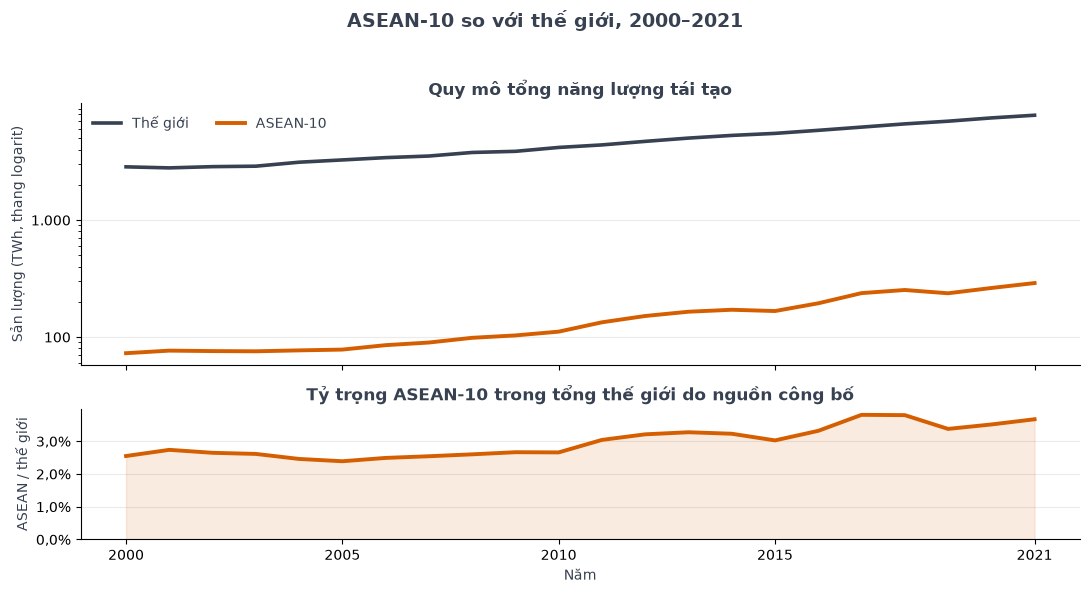

In [27]:
# Bước 5.2 — Tách sản lượng và tỷ trọng thành hai khung chung trục x để không cần trục kép.
years_plot = np.asarray(list(ANALYSIS_YEARS), dtype=int)
asean_total_plot = asean_totals["RENEWABLE_TOTAL"].to_numpy(dtype=float)
world_total_plot = world_totals["RENEWABLE_TOTAL"].to_numpy(dtype=float)
share_plot = asean_share_world["RENEWABLE_TOTAL"].to_numpy(dtype=float) * 100

fig, axes = plt.subplots(
    2, 1, figsize=(11, 6), dpi=100, sharex=True,
    gridspec_kw={"height_ratios": [2.0, 1.0]}
)
axes[0].plot(
    years_plot, world_total_plot, color=NEUTRAL_GRAY, linewidth=2.6, label="Thế giới"
)
axes[0].plot(
    years_plot, asean_total_plot, color=VIETNAM_HIGHLIGHT,
    linewidth=2.8, label="ASEAN-10"
)
axes[0].set_yscale("log")
axes[0].set_ylabel("Sản lượng (TWh, thang logarit)")
axes[0].set_title("Quy mô tổng năng lượng tái tạo")
axes[0].legend(frameon=False, ncol=2, loc="upper left")
axes[0].yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda value, _: format_vi_number(value, 0))
)
style_axis(axes[0])

axes[1].plot(years_plot, share_plot, color=VIETNAM_HIGHLIGHT, linewidth=2.8)
axes[1].fill_between(years_plot, share_plot, color=VIETNAM_HIGHLIGHT, alpha=0.12)
axes[1].set_ylabel("ASEAN / thế giới")
axes[1].set_xlabel("Năm")
axes[1].set_title("Tỷ trọng ASEAN-10 trong tổng thế giới do nguồn công bố")
axes[1].yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda value, _: f"{format_vi_number(value, 1)}%")
)
axes[1].set_xticks([2000, 2005, 2010, 2015, 2021])
axes[1].set_ylim(bottom=0)
style_axis(axes[1])
fig.suptitle("ASEAN-10 so với thế giới, 2000–2021", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

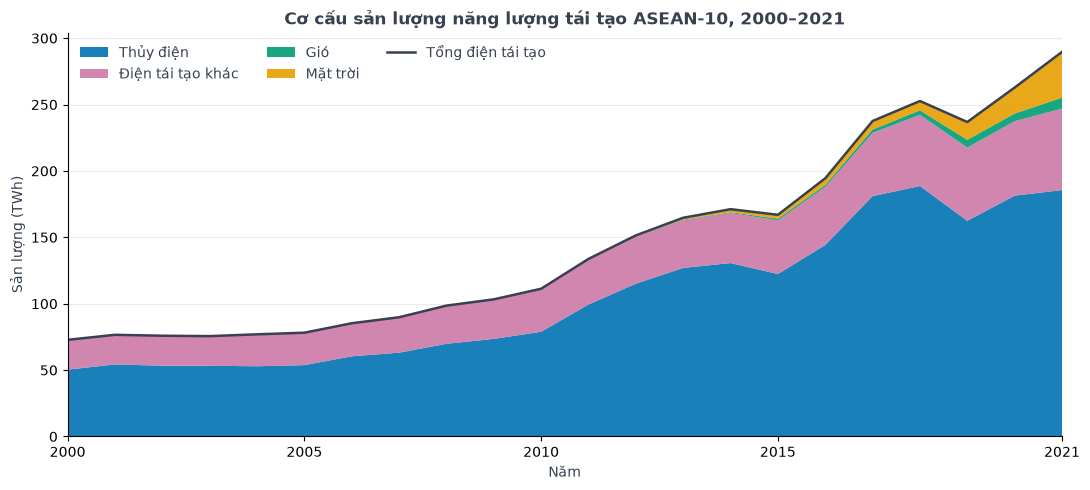

In [28]:
# Bước 5.3 — Chồng bốn thành phần có thể cộng để thấy đồng thời quy mô và dịch chuyển cơ cấu.
stack_order = ["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"]
stack_values = [asean_totals[key].to_numpy(dtype=float) for key in stack_order]
if any(np.isnan(values).any() for values in stack_values):
    raise ValueError("Không thể vẽ cơ cấu: tổng ASEAN có thành phần bị thiếu.")

fig, axis = plt.subplots(figsize=(11, 5), dpi=100)
axis.stackplot(
    years_plot,
    *stack_values,
    labels=[SERIES_LABELS_VI[key] for key in stack_order],
    colors=[TECHNOLOGY_COLORS[key] for key in stack_order],
    alpha=0.9,
)
axis.plot(
    years_plot, asean_total_plot, color=NEUTRAL_GRAY,
    linewidth=1.8, label="Tổng điện tái tạo",
)
axis.set_title("Cơ cấu sản lượng năng lượng tái tạo ASEAN-10, 2000–2021")
axis.set_xlabel("Năm")
axis.set_ylabel("Sản lượng (TWh)")
axis.set_xticks([2000, 2005, 2010, 2015, 2021])
axis.set_xlim(2000, 2021)
axis.set_ylim(bottom=0)
axis.yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda value, _: format_vi_number(value, 0))
)
axis.legend(frameon=False, ncol=3, loc="upper left")
style_axis(axis)
fig.tight_layout()
plt.show()

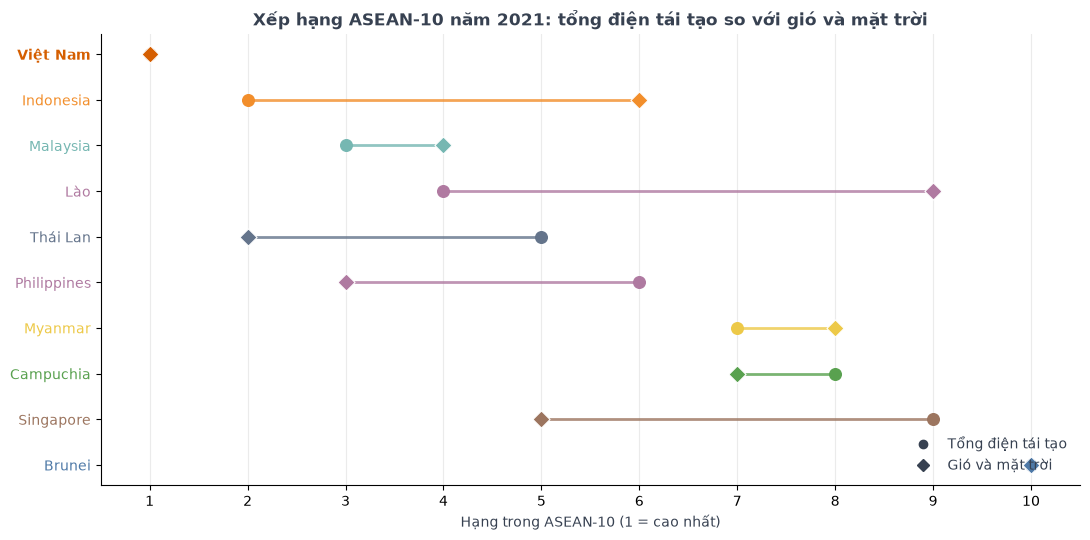

In [29]:
# Bước 5.4 — Nối hai hạng của cùng một nước để làm rõ mức đổi vị trí khi đổi thước đo.
ranking_2021 = (
    asean_rankings.loc[asean_rankings["year"].eq(2021)]
    .pivot(index="entity", columns="series", values="rank")
    .dropna(subset=["RENEWABLE_TOTAL", "MODERN_WIND_SOLAR"])
    .reset_index()
    .sort_values(["RENEWABLE_TOTAL", "entity"], kind="stable")
    .reset_index(drop=True)
)

fig, axis = plt.subplots(figsize=(11, 5.5), dpi=100)
y_positions = np.arange(len(ranking_2021))
for position, row in ranking_2021.iterrows():
    color = COUNTRY_COLORS[row["entity"]]
    is_vietnam = row["entity"] == "Vietnam"
    axis.plot(
        [row["RENEWABLE_TOTAL"], row["MODERN_WIND_SOLAR"]],
        [position, position],
        color=color,
        linewidth=3.2 if is_vietnam else 2.0,
        alpha=1.0 if is_vietnam else 0.8,
        zorder=2,
    )
    axis.scatter(
        row["RENEWABLE_TOTAL"], position, color=color, s=70, marker="o", zorder=3
    )
    axis.scatter(
        row["MODERN_WIND_SOLAR"], position, color=color, s=76,
        marker="D", edgecolor="white", linewidth=0.8, zorder=4
    )

axis.set_yticks(
    y_positions, [ENTITY_LABELS_VI[name] for name in ranking_2021["entity"]]
)
for tick, entity in zip(axis.get_yticklabels(), ranking_2021["entity"]):
    tick.set_color(COUNTRY_COLORS[entity])
    tick.set_fontweight("bold" if entity == "Vietnam" else "normal")
axis.invert_yaxis()
axis.set_xlim(0.5, 10.5)
axis.set_xticks(range(1, 11))
axis.set_xlabel("Hạng trong ASEAN-10 (1 = cao nhất)")
axis.set_title("Xếp hạng ASEAN-10 năm 2021: tổng điện tái tạo so với gió và mặt trời")
axis.legend(
    handles=[
        matplotlib.lines.Line2D(
            [], [], marker="o", linestyle="", color=NEUTRAL_GRAY, label="Tổng điện tái tạo"
        ),
        matplotlib.lines.Line2D(
            [], [], marker="D", linestyle="", color=NEUTRAL_GRAY, label="Gió và mặt trời"
        ),
    ],
    frameon=False,
    loc="lower right",
)
style_axis(axis, y_grid=False)
axis.grid(True, axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

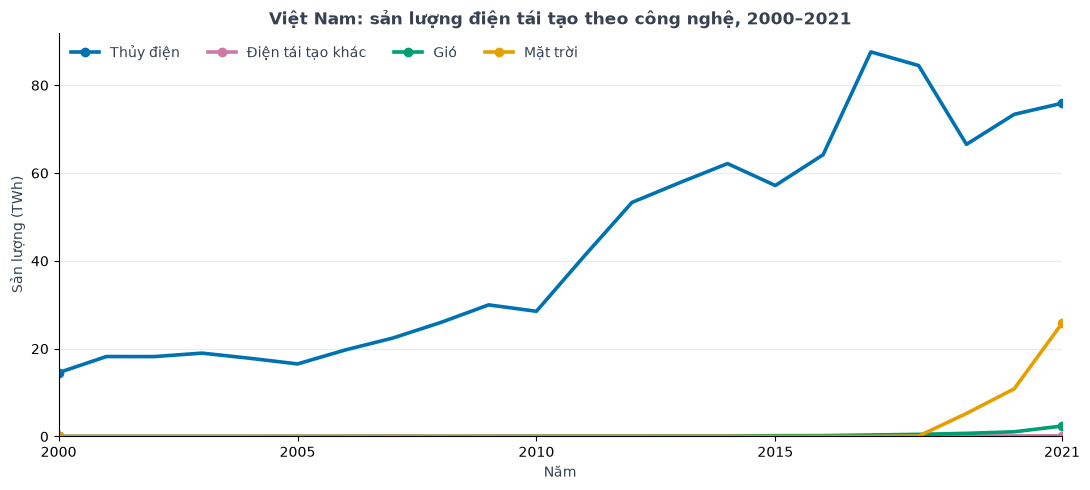

In [30]:
# Bước 5.5 — Giữ bốn đường trên cùng đơn vị TWh để so quỹ đạo mà không trộn thang đo.
vietnam_panel = asean_panel.loc[
    asean_panel["entity"].eq("Vietnam")
].sort_values("year")

fig, axis = plt.subplots(figsize=(11, 5), dpi=100)
for series in ["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"]:
    axis.plot(
        vietnam_panel["year"],
        vietnam_panel[series],
        color=TECHNOLOGY_COLORS[series],
        linewidth=2.6,
        marker="o",
        markevery=[0, -1],
        label=SERIES_LABELS_VI[series],
    )
axis.set_title("Việt Nam: sản lượng điện tái tạo theo công nghệ, 2000–2021")
axis.set_xlabel("Năm")
axis.set_ylabel("Sản lượng (TWh)")
axis.set_xticks([2000, 2005, 2010, 2015, 2021])
axis.set_xlim(2000, 2021)
axis.set_ylim(bottom=0)
axis.yaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda value, _: format_vi_number(value, 0))
)
axis.legend(frameon=False, ncol=4, loc="upper left")
style_axis(axis)
fig.tight_layout()
plt.show()

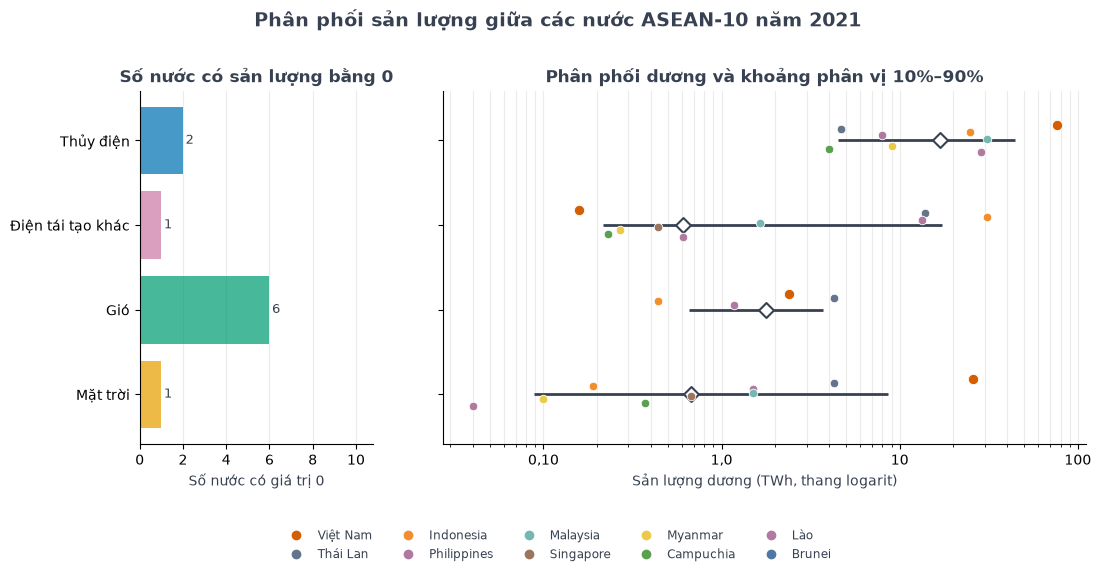

In [31]:
# Bước 5.6 — Đếm số 0 ở khung riêng; chỉ đưa giá trị > 0 vào trục logarit.
distribution_2021 = asean_panel.loc[asean_panel["year"].eq(2021)].melt(
    id_vars=["entity", "year"],
    value_vars=["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"],
    var_name="series",
    value_name="value",
)
zero_counts = (
    distribution_2021.assign(is_zero=distribution_2021["value"].eq(0))
    .groupby("series")["is_zero"]
    .sum()
    .reindex(["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"])
)
positive_distribution = distribution_2021.loc[
    distribution_2021["value"].gt(0)
].copy()
if not positive_distribution["value"].gt(0).all():
    raise AssertionError("Trục logarit nhận giá trị không dương.")

distribution_order = ["HYDRO", "OTHER_RENEWABLES", "WIND", "SOLAR"]
y_map = {series: index for index, series in enumerate(distribution_order)}
entity_offsets = dict(
    zip(ASEAN_COUNTRIES, np.linspace(-0.18, 0.18, len(ASEAN_COUNTRIES)))
)

fig, axes = plt.subplots(
    1, 2, figsize=(11, 5.8), dpi=100,
    gridspec_kw={"width_ratios": [0.8, 2.2]}, sharey=True
)
y_base = np.arange(len(distribution_order))
axes[0].barh(
    y_base,
    zero_counts.to_numpy(dtype=float),
    color=[TECHNOLOGY_COLORS[key] for key in distribution_order],
    alpha=0.72,
)
for position, count in enumerate(zero_counts):
    axes[0].text(float(count) + 0.12, position, str(int(count)), va="center", fontsize=9)
axes[0].set_xlim(0, 10.8)
axes[0].set_xticks(range(0, 11, 2))
axes[0].set_xlabel("Số nước có giá trị 0")
axes[0].set_title("Số nước có sản lượng bằng 0")
axes[0].set_yticks(y_base, [SERIES_LABELS_VI[key] for key in distribution_order])
axes[0].invert_yaxis()
style_axis(axes[0], y_grid=False)
axes[0].grid(True, axis="x", alpha=0.25)

for series in distribution_order:
    subset = positive_distribution.loc[positive_distribution["series"].eq(series)]
    y_position = y_map[series]
    if not subset.empty:
        p10, median, p90 = np.percentile(
            subset["value"].to_numpy(dtype=float), [10, 50, 90], method="linear"
        )
        axes[1].hlines(
            y_position, p10, p90, color=NEUTRAL_GRAY, linewidth=2.0, zorder=1
        )
        axes[1].scatter(
            median, y_position, color="white", edgecolor=NEUTRAL_GRAY,
            marker="D", s=58, linewidth=1.5, zorder=3
        )
    for row in subset.itertuples(index=False):
        axes[1].scatter(
            row.value,
            y_position + entity_offsets[row.entity],
            color=COUNTRY_COLORS[row.entity],
            s=55 if row.entity == "Vietnam" else 38,
            edgecolor="white",
            linewidth=0.6,
            zorder=4,
        )

axes[1].set_xscale("log")
axes[1].set_xlabel("Sản lượng dương (TWh, thang logarit)")
axes[1].set_title("Phân phối dương và khoảng phân vị 10%–90%")
axes[1].xaxis.set_major_formatter(
    matplotlib.ticker.FuncFormatter(
        lambda value, _: format_vi_number(
            value, 2 if value < 1 else 1 if value < 10 else 0
        )
    )
)
style_axis(axes[1], y_grid=False)
axes[1].grid(True, axis="x", which="both", alpha=0.25)

country_handles = [
    matplotlib.lines.Line2D(
        [], [], marker="o", linestyle="", color=COUNTRY_COLORS[entity],
        label=ENTITY_LABELS_VI[entity], markersize=6
    )
    for entity in ASEAN_COUNTRIES
]
fig.legend(
    handles=country_handles, frameon=False, loc="lower center",
    bbox_to_anchor=(0.5, 0.01), ncol=5, fontsize=8.5
)
fig.suptitle(
    "Phân phối sản lượng giữa các nước ASEAN-10 năm 2021",
    fontsize=14, fontweight="bold"
)
fig.subplots_adjust(left=0.12, right=0.98, top=0.84, bottom=0.23, wspace=0.16)
plt.show()

### Kết quả trực quan hóa và cách chạy lại

Hai khung của biểu đồ ASEAN–thế giới tách quy mô khỏi tỷ trọng nên không cần trục kép. Biểu đồ cơ cấu giữ đúng phép cộng bốn công nghệ; biểu đồ xếp hạng cho thấy tác động của việc đổi thước đo; chuỗi Việt Nam giữ cùng đơn vị TWh; biểu đồ phân phối bảo toàn số 0 ở khung riêng thay vì đẩy số 0 lên trục logarit bằng một hằng số tùy ý.

Để chạy lại, mở sổ tay trong thư mục dự án hoặc một thư mục con của dự án, khởi động lại môi trường Python rồi chạy các ô từ trên xuống dưới. Cần có đủ 17 tệp nguồn trong thư mục `archive/` và các thư viện đã liệt kê ở phần đầu. Kết quả được tính từ nguồn gốc trong bộ nhớ; sổ tay không ghi tệp dữ liệu. Việc chạy lại từ trạng thái mới giúp phát hiện phụ thuộc vào biến còn sót của phiên làm việc trước. Các hình giữ nguyên số 0 và phạm vi quan sát để hỗ trợ đọc đúng phân phối và xu hướng.